# ĐỒ ÁN COMPUTER VISION (VN-ALPR) — LPRNET v5
## Rà soát tập train bằng checkpoint v4 + Thêm chữ R + Nhận seri 2 chữ + Tách biển 2 dòng theo khe nghiêng

**Thay đổi của v5 so với v4 (và lý do):**

| Vấn đề ở v4 | Cách xử lý ở v5 |
| :--- | :--- |
| Ảnh lỗi / nhãn sai trong train **phạt sai mô hình** (vd. biển ghi 98-M2 nhưng nhãn 98N26985) | **Bước 10.1 rà soát**: checkpoint v4 đọc lại toàn bộ train, in các ảnh đọc khác nhãn theo CTC loss giảm dần, ghi `train_review.csv`, rồi **dừng notebook**. Bạn điền `drop` / `relabel` / `one_row` / `two_rows` vào `train_fixes.csv`, chạy lại để train trên dữ liệu đã sửa |
| Bảng ký tự không có **R** (biển rơ-moóc): 446 ảnh có ký tự ngoài bảng bị loại khỏi train, mô hình không thể đoán R | Thêm `R` (32 lớp). Trọng số lớp R lấy từ trọng số tác giả. Checkpoint v2–v4 (31 lớp) vẫn nạp được |
| Giải mã greedy **thêm ký tự thừa** (`890B199639`, `29H1174111`, `8B1H106876`) và nhầm chữ ↔ số; `fix_vn_plate` chỉ đổi chữ ↔ số, không bỏ được ký tự thừa | **Giải mã ràng buộc định dạng**: beam search CTC chỉ giữ chuỗi hợp lệ theo ngữ pháp học từ nhãn train (mã tỉnh, seri 1–2 chữ đã gặp, số chữ số theo 1/2 dòng). Báo cáo cả 3 kết quả: greedy, greedy + fix, ràng buộc |
| Chữ hiếm học kém: A có 11.111 mẫu nhưng Z 114, K 247, X 224, G 343 | **Lấy mẫu lặp ảnh có chữ hiếm** ×√(1000 / số lần), tối đa ×3, nhân với hệ số xe máy. Bảng **độ chính xác theo từng chữ cái** ở Bước 14 |
| Regex định dạng không nhận **seri 2 chữ + 6 số** (29-MD1 524.62): ảnh bị gắn "nhãn lạ" và loại khỏi train | Regex mới `^\d{2}[A-Z]{1,2}\d{4,6}$` |

**Thay đổi của v4 so với v3 (vẫn giữ nguyên ở v5):**

| Vấn đề ở v3 | Cách xử lý ở v4 |
| :--- | :--- |
| Tin hoàn toàn nhãn 1/2 dòng trong tên file. Ảnh biển 1 dòng bị gán nhãn 2 dòng sẽ bị **cắt đôi thành ảnh rác** (và ngược lại) | Áp dụng 21 ảnh sai nhãn layout + 1 bbox sai **đã xem tay ở notebook CRNN**. Tự tìm ảnh **nghi sai layout** theo tỉ lệ rộng/cao, in ảnh để xem, ghi CSV. Sửa thêm qua `layout_corrections.csv` |
| Cắt biển 2 dòng theo đường ngang cố định ở `h/2`. Biển xe máy nghiêng thì đường cắt **xuyên qua chữ** | **Tìm khe giữa 2 dòng chữ** (đường thẳng có thể nghiêng, cắt qua ít nét mực nhất), rồi **nắn từng dòng thẳng lại** bằng `cv2.remap` trước khi resize về 94×24. Có cờ "tách không chắc chắn" để xem lại |
| Chia tập chỉ theo chuỗi biển số. Ảnh **giống hệt từng byte** nhưng khác nhãn có thể rơi vào cả train và test | Chia tập theo **nhóm liên thông: cùng biển số HOẶC cùng sha256** |
| Loại ảnh lỗi (bbox sai, nhãn lạ) khỏi **cả tập test**, nên số liệu test hơi lạc quan | Train chỉ dùng mẫu sạch. **Val/Test giữ mọi mẫu**; ảnh không đọc được hoặc bbox sai cho dự đoán rỗng và **tính là sai** |
| Không biết lỗi tập trung ở ảnh khó nào | **Cờ chất lượng** (mờ, crop nhỏ, tách không chắc, nhãn lạ) và bảng kết quả Test theo từng cờ |
| Lỗi pipeline chỉ lộ ra sau nhiều giờ train | **Sanity check**: mô hình phải học thuộc 32 ảnh trước khi train thật. `CTCLoss(zero_infinity=False)`. Checkpoint lưu **dấu vân tay dữ liệu**, resume khi dữ liệu đã đổi sẽ bị chặn |

**Thay đổi của v3 so với v2 (vẫn giữ nguyên ở v5):**

| Vấn đề ở v2 | Cách xử lý ở v3 |
| :--- | :--- |
| Biển 2 dòng ghép 2 nửa vào chung 94×24, mỗi dòng chỉ còn 47 px và khoảng **9 bước CTC**. Dòng dưới có 5 chữ số, thêm dấu chấm, lại cần blank chen giữa các số lặp, nên mô hình **mất ký tự**, nhất là số lặp (`99→9`, `555→55`). Xe máy kẹt ở ~64% | Mỗi dòng được resize riêng về **94×24 như một biển 1 dòng** rồi ghép ngang thành **188×24**. Đầu ra tăng từ 18 lên **42 bước** (khoảng 21 bước mỗi dòng). Biển 1 dòng vẫn giữ 94×24 |
| Global Context dùng avgpool kích thước cố định, chỉ chạy được với ảnh rộng 94 | Giữ nguyên avgpool gốc (cùng tỉ lệ cửa sổ), sau đó **nội suy về đúng độ rộng đầu ra** nếu cần. Với ảnh 94 kết quả **giống hệt** bản gốc, nên vẫn transfer 100% |
| Một batch không thể chứa ảnh khác chiều rộng | **Batch theo nhóm**: mỗi batch chỉ có ảnh 94 hoặc chỉ có ảnh 188, thứ tự các batch được xáo. Vẫn lấy mẫu xe máy ×2.5 |
| Augmentation chồng nhiều phép làm xấu ảnh (tối + mờ + giảm phân giải + JPEG), sinh ra mẫu mắt người cũng không đọc được, thành nhiễu nhãn | Thu hẹp biên độ sáng/tối. **Mỗi ảnh tối đa 1 phép làm suy giảm** (mờ / phân giải thấp / JPEG). Nếu ảnh sau augmentation mất quá nửa độ tương phản thì dùng lại ảnh chưa làm xấu |

**Những gì v2 đã thay đổi so với notebook cũ (vẫn giữ nguyên ở v5):**

| Vấn đề ở bản cũ | Cách xử lý ở bản v2 |
| :--- | :--- |
| Kiến trúc tự viết khác bản gốc nên chỉ nạp được **8/47** tensor, thực chất là train từ đầu | Dùng **đúng kiến trúc sirius-ai/LPRNet_Pytorch** (có Global Context, SmallBasicBlock không residual) nên nạp được **100%** trọng số. 3 tầng phụ thuộc số lớp được **cắt theo ký tự chung** (0–9, chữ Latinh) thay vì khởi tạo ngẫu nhiên |
| Không crop khi bbox rộng gần bằng ảnh, rồi heuristic `h/w > 0.65` **cắt đôi cả ảnh toàn cảnh** (ra lưới tản nhiệt + mặt đường) | Luôn crop theo bbox (có đệm). Chỉ cắt đôi khi nhãn là biển 2 dòng |
| Cắt đôi đúng `h/2`, mất hoặc lặp ký tự ở chỗ nối hai dòng | Cắt đôi **chồng lấn 5%** |
| `cv2.imread` tự xoay ảnh theo EXIF nên lệch với bbox | Đọc theo pixel gốc, kiểm tra bbox nằm trong ảnh, xem trực quan các ảnh có cờ EXIF |
| Ký tự ngoài bảng bị **xóa khỏi nhãn** (nhãn bị ngắn đi) | `O→0`, `I→1`. Ký tự lạ khác thì bỏ cả mẫu. Kiểm tra định dạng biển VN |
| Augmentation chỉ chỉnh sáng/tối | Lệch bbox (mô phỏng YOLO), xoay/nghiêng, phối cảnh, mờ, nhiễu, JPEG, độ phân giải thấp. **Không lật ảnh** |
| Xe máy chỉ chiếm ~15% dữ liệu | Lấy mẫu lặp xe máy ×2.5 (`WeightedRandomSampler`) |
| LR 1e-4 + Cosine về 0 sau 40 epoch, loss vẫn còn giảm (chưa hội tụ) | Pha 1: 3 epoch đóng băng. Pha 2: 80 epoch AdamW + OneCycleLR (max 1e-3) |
| Đo FPS không đồng bộ GPU | Có `torch.cuda.synchronize()`, đo thêm thời gian tiền xử lý |

**Cách chạy:** Runtime GPU, sau đó *Run all*. Kết quả lưu vào `TGMT/lprnet_v5/`, không đụng tới các thư mục cũ.
- **Lần chạy đầu (`REVIEW_MODE = True`)**: notebook chạy tới Bước 10.1 rồi **dừng có chủ ý** để bạn rà soát ảnh lỗi. Sửa xong `train_fixes.csv` thì đặt `REVIEW_MODE = False` và *Run all* để train.
- `WEIGHTS_MODE = "author"` (mặc định): transfer từ trọng số tác giả, số liệu sạch cho báo cáo. `"prev"`: khởi tạo từ checkpoint của bản trước (`PREV_BEST_PATH`).
- Bước 4 in các ảnh **nghi sai nhãn 1/2 dòng**. Ảnh nào sai thật thì thêm vào `TGMT/lprnet_v5/layout_corrections.csv` (cột `file,layout`) rồi chạy lại từ Bước 3.
- **Split khác v2/v3** (vì gom thêm ảnh trùng và giữ mẫu lỗi trong test), nên số liệu v4 không so trực tiếp từng con số với v3.
- Bước 7 in ảnh trước/sau tiền xử lý. Bước 7.2 **tự dừng** nếu phát hiện nhiều ảnh đầu vào bị trơn hoặc hỏng.
- Colab bị ngắt giữa chừng: đặt `WEIGHTS_MODE = "resume"` ở Bước 1 rồi *Run all*, notebook train tiếp từ epoch cuối.
- Chỉ muốn đánh giá lại: chạy Bước 1 đến 10, rồi nhảy tới Bước 13.
- Nối với MobileNetV3-Small (LPRNet làm OCR chính): chạy Bước 1 đến 10, rồi Bước 15.1 đến 15.5 (không cần train lại).


In [1]:
# 0. Cài thư viện (opencv, torch, matplotlib đã có sẵn trên Colab)
!pip install -q editdistance

### 1. Cấu Hình Chung (chỉ cần chỉnh ở ô này)

In [2]:
# ==============================================================================
# BƯỚC 1: CẤU HÌNH CHUNG
# ==============================================================================
import os, re, json, time, math, random, shutil, functools, traceback
from collections import Counter, defaultdict

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import editdistance

# --- Đường dẫn ---
DRIVE_DIR      = "/content/drive/MyDrive/TGMT"
ZIP_PATH       = f"{DRIVE_DIR}/VNLP_detection.zip"
DATASET_DIR    = "/content/dataset"
LOCAL_DIR      = "/content/weights"
SAVE_DIR       = f"{DRIVE_DIR}/lprnet_v5"          # thư mục mới, KHÔNG ghi đè kết quả cũ
AUTHOR_WEIGHTS = f"{LOCAL_DIR}/Final_LPRNet_model.pth"
PREV_BEST_PATH = f"{DRIVE_DIR}/lprnet_v4/best_lprnet_vn_v4.pth"   # checkpoint v4 (31 lớp) cũng nạp được, lớp R lấy từ trọng số tác giả
BEST_PATH      = f"{SAVE_DIR}/best_lprnet_vn_v5.pth"
LAST_PATH      = f"{SAVE_DIR}/last_lprnet_vn_v5.pth"
LAYOUT_FIX_CSV = f"{SAVE_DIR}/layout_corrections.csv"  # sửa tay nhãn 1/2 dòng: cột file,layout (one_row/two_rows)
TRAIN_FIX_CSV  = f"{SAVE_DIR}/train_fixes.csv"         # sửa tay sau khi rà soát: cột file,action,new_label (Bước 10.1)

# --- Rà soát tập train bằng checkpoint cũ (Bước 10.1) ---
# True : dự đoán tập train bằng REVIEW_CKPT, in ảnh nghi lỗi, ghi train_review.csv rồi DỪNG notebook (chưa train)
# False: bỏ qua rà soát, train bình thường (đặt False sau khi đã sửa xong train_fixes.csv)
REVIEW_MODE     = False
REVIEW_CKPT     = f"{DRIVE_DIR}/lprnet_v4/last_lprnet_vn_v4.pth"
REVIEW_SPLITS   = ("Train",)   # có thể thêm "Val", "Test" để rà cả nhãn của 2 tập đánh giá
REVIEW_PAGE     = 1            # trang ảnh đang xem (mỗi trang REVIEW_PER_PAGE ảnh, xếp theo loss giảm dần)
REVIEW_PER_PAGE = 40

# --- Chế độ trọng số ---
# "author": transfer learning từ Final_LPRNet_model.pth của tác giả (chạy lần đầu, số liệu sạch cho báo cáo)
# "prev"  : khởi tạo từ PREV_BEST_PATH (cùng kiến trúc, hội tụ nhanh hơn)
# "resume": train tiếp từ LAST_PATH trên Drive (khi Colab bị ngắt giữa chừng)
WEIGHTS_MODE = "author"

# --- Tiền xử lý ---
IMG_W, IMG_H        = 94, 24     # kích thước của MỘT dòng (đúng kích thước đầu vào LPRNet gốc)
IMG_W2              = 2 * IMG_W  # biển 2 dòng: dòng trên | dòng dưới, mỗi dòng 94x24 -> 188x24
PAD_X, PAD_Y        = 0.03, 0.06 # đệm quanh bbox khi đánh giá / suy luận (tỉ lệ theo kích thước bbox)
SPLIT_METHOD        = "sloped"   # "sloped": tìm khe nghiêng giữa 2 dòng | "horizontal": cắt ngang ở h/2 như v3 (để so sánh)
SPLIT_OVERLAP       = 0.03       # mỗi dòng lấn qua đường tách 3% chiều cao, tránh mất chân/đầu chữ
EXIF_MODE           = "ignore"   # "ignore": đọc theo pixel gốc | "apply": xoay ảnh theo cờ EXIF
DROP_INVALID_LABELS = True       # bỏ khỏi TRAIN các nhãn không đúng định dạng biển số VN (val/test vẫn giữ)

# --- Kiểm tra trước khi train ---
SANITY_SIZE, SANITY_STEPS, SANITY_MIN_ACC = 32, 400, 0.95   # mô hình phải học thuộc 32 ảnh

# --- Huấn luyện ---
SEED            = 42
BATCH_SIZE      = 128
NUM_WORKERS     = min(8, os.cpu_count() or 2)
MOTO_WEIGHT     = 2.5   # hệ số lấy mẫu lặp cho biển xe máy
RARE_REF        = 1000  # chữ cái xuất hiện ít hơn RARE_REF lần trong train được lấy mẫu lặp ×sqrt(RARE_REF / số lần)
RARE_MAX        = 3.0   # hệ số lặp tối đa cho một ảnh có chữ hiếm
BEAM_WIDTH      = 10    # số giả thuyết giữ lại khi giải mã có ràng buộc định dạng (Bước 10)
FROZEN_EPOCHS   = 3     # Pha 1: chỉ train các tầng phụ thuộc số lớp (số liệu "Frozen" cho TN-OCR 1)
FINETUNE_EPOCHS = 80    # Pha 2: fine-tune toàn mạng
LR_HEAD         = 1e-3
MAX_LR          = 1e-3
WEIGHT_DECAY    = 1e-4
DROPOUT         = 0.3

# --- Tự ngắt Colab khi rảnh ---
ENABLE_AUTO_DISCONNECT = True
IDLE_TIMEOUT_MINUTES   = 30

os.makedirs(LOCAL_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
cv2.setNumThreads(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("-> Thiết bị:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

def idle_shutdown_timer(timeout_minutes=IDLE_TIMEOUT_MINUTES):
    if not ENABLE_AUTO_DISCONNECT:
        print("-> Cơ chế tự động ngắt phiên đang TẮT.")
        return
    from google.colab import runtime
    total_seconds = int(timeout_minutes * 60)
    print()
    print("=" * 76)
    print(f"⏰ KÍCH HOẠT HẸN GIỜ TỰ ĐỘNG NGẮT PHIÊN (IDLE SHUTDOWN): {timeout_minutes} PHÚT")
    print("👉 BẤM NÚT DỪNG (STOP Ở CELL NÀY) BẤT KỲ LÚC NÀO ĐỂ HỦY NGẮT VÀ TIẾP TỤC LÀM VIỆC!")
    print("=" * 76)
    try:
        start_time = time.time()
        while True:
            remaining = total_seconds - (time.time() - start_time)
            if remaining <= 0:
                break
            print(f"\r⏳ Thời gian chờ còn lại trước khi ngắt GPU: {int(remaining // 60):02d} phút {int(remaining % 60):02d} giây...", end="", flush=True)
            time.sleep(5)
        print()
        print(f"-> ĐÃ HẾT {timeout_minutes} PHÚT! Đang giải phóng GPU Colab...")
        time.sleep(5)
        runtime.unassign()
    except KeyboardInterrupt:
        print()
        print("* ĐÃ HỦY LỆNH NGẮT PHIÊN THÀNH CÔNG! Giữ nguyên phiên Colab để tiếp tục làm việc. *")

-> Thiết bị: cuda | NVIDIA A100-SXM4-40GB


### 2. Kết Nối Google Drive & Giải Nén Dữ Liệu

In [3]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(SAVE_DIR, exist_ok=True)

if not os.path.exists(f"{DATASET_DIR}/detection"):
    os.makedirs(DATASET_DIR, exist_ok=True)
    !unzip -q "{ZIP_PATH}" -d "{DATASET_DIR}"
print("Cấu trúc thư mục tại", DATASET_DIR, ":", os.listdir(DATASET_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cấu trúc thư mục tại /content/dataset : ['detection']


### 3. Parser Dữ Liệu VNLP
Tên file: `ID1_ID2_ROWTYPE_LABEL_XMIN_YMIN_XMAX_YMAX.jpg` (`ROWTYPE`: `1` = 1 dòng, `0` = 2 dòng).

Khác bản cũ: ký tự ngoài bảng **không còn bị xóa âm thầm khỏi nhãn**. `O→0`, `I→1` (biển VN không dùng chữ O, I). Nhãn còn ký tự lạ khác thì **không dùng để train**, nhưng vẫn giữ trong Val/Test và tính là sai nếu đoán không khớp.

In [4]:
# Bảng ký tự biển số VN: 30 ký tự của v2–v4 + R (biển rơ-moóc) + 1 blank cho CTC (32 lớp)
V4_CHARS = [
    '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'K', 'L', 'M',
    'N', 'P', 'S', 'T', 'U', 'V', 'X', 'Y', 'Z'
]
EXTRA_CHARS = ['R']   # chữ thêm ở v5, phải có trong bảng ký tự của trọng số tác giả
CHARS = V4_CHARS + EXTRA_CHARS
CHARS_DICT  = {c: i for i, c in enumerate(CHARS)}
BLANK_IDX   = len(CHARS)
NUM_CLASSES = len(CHARS) + 1
GROUPS      = ["1 dòng", "2 dòng ô tô", "xe máy"]
LABEL_FIX   = {"O": "0", "I": "1"}
parse_stats = Counter()

def parse_vnlp_file(txt_path, group, base_dir=DATASET_DIR):
    samples = []
    if not os.path.exists(txt_path):
        print(f"Không tìm thấy file: {txt_path}")
        return samples
    with open(txt_path, "r", encoding="utf-8") as f:
        for line in f:
            rel_path = line.strip()
            if not rel_path:
                continue
            clean_rel = rel_path.lstrip("/")
            full_path = os.path.join(base_dir, clean_rel)
            if not os.path.exists(full_path):
                alt_path = os.path.join(base_dir, clean_rel.replace("detection/", ""))
                if os.path.exists(alt_path):
                    full_path = alt_path

            tokens = os.path.splitext(os.path.basename(rel_path))[0].split("_")
            if len(tokens) < 8:
                parse_stats["tên file sai định dạng"] += 1
                continue
            try:
                xmin, ymin, xmax, ymax = map(int, tokens[4:8])
            except ValueError:
                parse_stats["bbox không phải số"] += 1
                continue
            raw = tokens[3].upper()
            label = "".join(LABEL_FIX.get(c, c) for c in raw)
            if label != raw:
                parse_stats["nhãn được sửa O→0 / I→1"] += 1
            if any(c not in CHARS_DICT for c in label):
                parse_stats["nhãn có ký tự ngoài bảng (không train)"] += 1
            samples.append({
                "img_path": full_path,
                "label": label,
                "label_orig": label,   # nhãn trong tên file, dùng để chia tập (không đổi khi sửa nhãn tay)
                "group": group,
                "is_two_rows": tokens[2] == "0",
                "bbox": (xmin, ymin, xmax, ymax),
            })
    return samples

txt_root = f"{DATASET_DIR}/detection" if os.path.exists(f"{DATASET_DIR}/detection") else DATASET_DIR
all_samples = (parse_vnlp_file(f"{txt_root}/list_one_row.txt", "1 dòng")
             + parse_vnlp_file(f"{txt_root}/list_two_row.txt", "2 dòng ô tô")
             + parse_vnlp_file(f"{txt_root}/list_two_rows_label_xe_may.txt", "xe máy"))

print(f"-> Tổng số mẫu nạp được: {len(all_samples)}")
for g in GROUPS:
    print(f"   • {g:12s}: {sum(s['group'] == g for s in all_samples)}")
for k, v in parse_stats.items():
    print(f"   [parser] {k}: {v}")
odd_chars = Counter(c for s in all_samples for c in s["label"] if c not in CHARS_DICT)
if odd_chars:
    print(f"   [parser] các ký tự ngoài bảng (số lần): {dict(odd_chars.most_common())}")

# Đối chiếu nhóm (theo file list) với ROWTYPE trong tên file
print("Đối chiếu nhóm và ROWTYPE (tên file):")
for g in GROUPS:
    c = Counter(s["is_two_rows"] for s in all_samples if s["group"] == g)
    print(f"   • {g:12s}: 1 dòng = {c[False]:6d} | 2 dòng = {c[True]:6d}")

-> Tổng số mẫu nạp được: 37297
   • 1 dòng      : 19086
   • 2 dòng ô tô : 12618
   • xe máy      : 5593
   [parser] nhãn được sửa O→0 / I→1: 1
Đối chiếu nhóm và ROWTYPE (tên file):
   • 1 dòng      : 1 dòng =  19086 | 2 dòng =      0
   • 2 dòng ô tô : 1 dòng =      0 | 2 dòng =  12618
   • xe máy      : 1 dòng =      0 | 2 dòng =   5593


### 4. Kiểm Tra & Làm Sạch Dữ Liệu (bbox, EXIF, nhãn 1/2 dòng, ảnh trùng) Trước Khi Chia Tập
Mỗi ảnh được xếp vào một trong các loại:
- `full`: ảnh toàn cảnh, bbox nằm trong ảnh, sẽ crop theo bbox.
- `crop`: ảnh đã là ảnh cắt sẵn của biển số, dùng nguyên ảnh.
- `bad_bbox` hoặc `unreadable`: **không dùng để train**. Trong Val/Test vẫn giữ: đầu vào là ảnh xám, dự đoán rỗng, **tính là sai**.

Sau đó ô này:
1. **Sửa nhãn 1/2 dòng đã xác nhận bằng mắt**: 21 ảnh sai layout và 1 ảnh bbox sai tìm được ở notebook CRNN, cộng với các dòng trong `layout_corrections.csv`.
2. **Tìm ảnh nghi sai nhãn 1/2 dòng** theo tỉ lệ rộng/cao bbox: nhãn 2 dòng mà rộng/cao ≥ 2.5, hoặc nhãn 1 dòng mà rộng/cao ≤ 2.0. Đây chỉ là gợi ý, **phải xem ảnh rồi mới sửa** (xem hướng dẫn ở ô ảnh bên dưới).
3. Tính **sha256** từng ảnh để gom ảnh trùng khi chia tập.
4. Tìm ngưỡng rộng/cao bbox để **đoán biển 1 dòng hay 2 dòng từ bbox YOLO** khi chạy pipeline thực tế.

In [5]:
import io, csv, hashlib
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# 2 số tỉnh + seri 1-2 chữ + 4-6 số: 30A12345, 30A1234, 51LD12345, 29H174111, 29MD152462
VN_PLATE_RE = re.compile(r"^[0-9]{2}[A-Z]{1,2}[0-9]{4,6}$")
EXIF_ROTATED = (5, 6, 7, 8)
IMREAD_FLAGS = cv2.IMREAD_COLOR | (cv2.IMREAD_IGNORE_ORIENTATION if EXIF_MODE == "ignore" else 0)

def read_image(path):
    return cv2.imread(path, IMREAD_FLAGS)

def out_steps(w):
    # số bước thời gian đầu ra của LPRNet với ảnh rộng w (conv 3x3, 3 maxpool, conv 1x4)
    w = w - 4
    w = (w - 3) // 2 + 1
    w = (w - 3) // 2 + 1
    return w - 3

def input_width(s):
    return IMG_W2 if s["is_two_rows"] else IMG_W

T_STEPS = {IMG_W: out_steps(IMG_W), IMG_W2: out_steps(IMG_W2)}
print(f"-> Số bước CTC: ảnh {IMG_W}x{IMG_H} = {T_STEPS[IMG_W]} | ảnh {IMG_W2}x{IMG_H} = {T_STEPS[IMG_W2]}")

def inspect_image(s):
    try:
        with open(s["img_path"], "rb") as f:
            data = f.read()
        sha = hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            w, h = im.size                       # kích thước pixel gốc (chưa xoay EXIF)
            orient = im.getexif().get(274, 1)
    except Exception:
        return "unreadable", 0, 0, 1, None
    if EXIF_MODE == "apply" and orient in EXIF_ROTATED:
        w, h = h, w
    xmin, ymin, xmax, ymax = s["bbox"]
    bw, bh = xmax - xmin, ymax - ymin
    if bw < 8 or bh < 4:
        return "bad_bbox", w, h, orient, sha
    tx, ty = 0.02 * w, 0.02 * h
    if xmin >= -tx and ymin >= -ty and xmax <= w + tx and ymax <= h + ty:
        mode = "crop" if (bw >= 0.9 * w and bh >= 0.9 * h) else "full"
    elif abs(w - bw) <= 0.25 * bw and abs(h - bh) <= 0.25 * bh:
        mode = "crop"                            # ảnh đã cắt sẵn, bbox theo toạ độ ảnh gốc
    else:
        mode = "bad_bbox"
    return mode, w, h, orient, sha

with ThreadPoolExecutor(max_workers=32) as ex:
    infos = list(ex.map(inspect_image, all_samples))
for s, (mode, w, h, orient, sha) in zip(all_samples, infos):
    s.update(mode=mode, img_w=w, img_h=h, exif=orient, sha256=sha, layout_label=s["is_two_rows"])

# --- 4.1 Sửa nhãn 1/2 dòng và bbox đã xác nhận bằng mắt ---
# Danh sách lấy từ notebook CRNN_BiLSTM_CTC_VNLP (đã xem từng ảnh). Khớp theo tiền tố tên file.
# False = biển 1 dòng, True = biển 2 dòng.
KNOWN_LAYOUT_FIXES = {
    **{p: False for p in [
        "3_210_0_36A05680_", "6_1697_0_22A07557_", "6_1703_0_28C02747_", "6_2345_0_36A23747_",
        "6_2459_0_36A29035_", "6_2477_0_36A30544_", "6_2620_0_36A41816_", "6_2764_0_36A42144_",
        "6_2943_0_36B01159_", "6_3129_0_36C02489_", "6_3625_0_36C29007_", "6_4068_0_36C25362_",
        "7_2317_0_29M2972_", "7_3031_0_36A27374_", "7_3313_0_36A42616_", "7_4295_0_36C17317_"]},
    **{p: True for p in [
        "1_4015_1_36C25648_135_305_215_386.jpg", "1_4120_1_36C27682_119_278_193_354.jpg",
        "4_3181_1_36C27959_242_251_375_332.jpg", "7_2790_1_36A15181_178_220_407_344.jpg",
        "7_2817_1_36A16143_204_161_496_312.jpg"]},
}
KNOWN_BAD_BBOX = ["1_3823_1_36C09937_6_232_83_295.jpg"]

def load_layout_csv(path):
    if not os.path.exists(path):
        return {}
    out = {}
    with open(path, encoding="utf-8-sig") as f:
        for r in csv.DictReader(f):
            layout = r["layout"].strip()
            assert layout in ("one_row", "two_rows"), f"Cột layout phải là one_row/two_rows: {r}"
            out[os.path.basename(r["file"].strip())] = layout == "two_rows"
    print(f"-> Đọc {len(out)} dòng sửa tay từ {path}")
    return out

layout_fixes = {**KNOWN_LAYOUT_FIXES, **load_layout_csv(LAYOUT_FIX_CSV)}
by_name = defaultdict(list)
for s in all_samples:
    by_name[os.path.basename(s["img_path"])].append(s)
names = sorted(by_name)

unmatched = []

def match_names(key):
    hits = [n for n in names if n.startswith(key)]
    if len(hits) != 1:
        unmatched.append(f"{key} ({len(hits)} file)")
    return hits if len(hits) == 1 else []

n_changed = 0
for key, two in layout_fixes.items():
    for n in match_names(key):
        for s in by_name[n]:
            s["layout_reviewed"] = True
            if s["is_two_rows"] != two:
                s["is_two_rows"] = two
                n_changed += 1
for key in KNOWN_BAD_BBOX:
    for n in match_names(key):
        for s in by_name[n]:
            s["mode"] = "bad_bbox"
n_bad_manual = sum(s["mode"] == "bad_bbox" and any(os.path.basename(s["img_path"]).startswith(k) for k in KNOWN_BAD_BBOX) for s in all_samples)
print(f"-> Đã sửa nhãn 1/2 dòng cho {n_changed} ảnh | đánh dấu bbox sai (xem tay): {n_bad_manual} ảnh")
if unmatched:
    print(f"   [CẢNH BÁO] {len(unmatched)} mục sửa tay không khớp đúng 1 file (bỏ qua), vd: {unmatched[:3]}")

# --- 4.1b Sửa tay sau khi rà soát tập train (train_fixes.csv, Bước 10.1) ---
# action: drop (bỏ khỏi train) | relabel (đổi nhãn thành new_label) | one_row / two_rows (sửa nhãn 1/2 dòng)
# Dòng có action trống thì bỏ qua, nên có thể sửa thẳng file train_review.csv rồi lưu thành train_fixes.csv.
def load_train_fixes(path):
    if not os.path.exists(path):
        return []
    rows = []
    with open(path, encoding="utf-8-sig") as f:
        for r in csv.DictReader(f):
            action = (r.get("action") or "").strip().lower()
            if not action:
                continue
            assert action in ("drop", "relabel", "one_row", "two_rows"), f"action không hợp lệ: {r}"
            new_label = (r.get("new_label") or "").strip().upper()
            if action == "relabel":
                assert new_label, f"relabel cần cột new_label: {r}"
            rows.append((os.path.basename(r["file"].strip()), action, new_label))
    return rows

fix_cnt, fix_missing = Counter(), []
for name, action, new_label in load_train_fixes(TRAIN_FIX_CSV):
    if name not in by_name:
        fix_missing.append(name)
        continue
    for s in by_name[name]:
        fix_cnt[action] += 1
        if action == "drop":
            s["manual_drop"] = True
        elif action == "relabel":
            s["label"] = new_label
        else:
            s["is_two_rows"] = action == "two_rows"
if fix_cnt or fix_missing:
    print(f"-> train_fixes.csv: {dict(fix_cnt)}" + (f" | {len(fix_missing)} file không tìm thấy, vd: {fix_missing[:3]}" if fix_missing else ""))

# --- 4.2 Loại khỏi TRAIN (Val/Test vẫn giữ) ---
def ctc_len(label):
    # CTC cần thêm 1 blank giữa 2 ký tự giống nhau liền kề
    return len(label) + sum(a == b for a, b in zip(label, label[1:]))

def drop_reason(s):
    if s["mode"] in ("unreadable", "bad_bbox"):
        return s["mode"]
    if s.get("manual_drop"):
        return "loại tay (train_fixes.csv)"
    if any(c not in CHARS_DICT for c in s["label"]):
        return "nhãn có ký tự ngoài bảng"
    if ctc_len(s["label"]) > T_STEPS[input_width(s)]:
        return "nhãn quá dài cho CTC"
    if DROP_INVALID_LABELS and not VN_PLATE_RE.match(s["label"]):
        return "nhãn sai định dạng VN"
    return "OK"

for s in all_samples:
    s["drop"] = drop_reason(s)
    s["input_ok"] = s["mode"] in ("full", "crop")   # False: đầu vào là ảnh xám, dự đoán rỗng

modes = ["full", "crop", "bad_bbox", "unreadable"]
mode_cnt = Counter((s["group"], s["mode"]) for s in all_samples)
print()
print("LOẠI ẢNH THEO NHÓM:")
print(f"{'Nhóm':14s}" + "".join(f"{m:>12s}" for m in modes) + f"{'EXIF xoay':>12s}")
for g in GROUPS:
    n_exif = sum(s["group"] == g and s["exif"] in EXIF_ROTATED for s in all_samples)
    print(f"{g:14s}" + "".join(f"{mode_cnt[(g, m)]:12d}" for m in modes) + f"{n_exif:12d}")

reasons = sorted({s["drop"] for s in all_samples} - {"OK"})
print()
print("SỐ MẪU KHÔNG DÙNG ĐỂ TRAIN THEO LÝ DO (Val/Test vẫn giữ):")
for r in reasons:
    print(f"   • {r:26s}: " + " | ".join(f"{g} = {sum(s['group'] == g and s['drop'] == r for s in all_samples)}" for g in GROUPS))
bad_labels = [s["label"] for s in all_samples if s["drop"] == "nhãn sai định dạng VN"]
if bad_labels:
    print("   Ví dụ nhãn sai định dạng:", bad_labels[:25])

clean_samples = [s for s in all_samples if s["drop"] == "OK"]

# Ước tính số mẫu từng bị lỗi tiền xử lý ở bản cũ (không crop vì bbox rộng gần bằng ảnh)
def old_pipeline_broken(s):
    xmin, ymin, xmax, ymax = s["bbox"]
    return s["mode"] == "full" and not (s["img_w"] > (xmax - xmin) * 1.2 and s["img_h"] > (ymax - ymin) * 1.2)

print()
print("ƯỚC TÍNH SỐ MẪU BỊ HỎNG TIỀN XỬ LÝ Ở BẢN CŨ (bây giờ đã sửa):")
for g in GROUPS:
    n_g = sum(s["group"] == g for s in clean_samples)
    n_b = sum(s["group"] == g and old_pipeline_broken(s) for s in clean_samples)
    print(f"   • {g:12s}: {n_b:6d} / {n_g:6d} ({100 * n_b / max(1, n_g):.1f}%)")

# --- 4.3 Ngưỡng tỉ lệ rộng/cao bbox để đoán 1 dòng / 2 dòng (dùng khi chạy pipeline với bbox YOLO) ---
def plate_ratio(s):
    if s["mode"] == "crop":
        return s["img_w"] / max(1, s["img_h"])
    xmin, ymin, xmax, ymax = s["bbox"]
    return (xmax - xmin) / max(1, ymax - ymin)

ratios = np.array([plate_ratio(s) for s in clean_samples])
is_two = np.array([s["is_two_rows"] for s in clean_samples])
ths = np.arange(1.2, 4.51, 0.05)
accs = [((ratios < t) == is_two).mean() for t in ths]
TWO_ROW_RATIO_THR = float(ths[int(np.argmax(accs))])
print()
print(f"-> Ngưỡng rộng/cao để đoán biển 2 dòng từ bbox: < {TWO_ROW_RATIO_THR:.2f} (đúng {100 * max(accs):.2f}% mẫu)")
print(f"-> Số mẫu dùng được để train: {len(clean_samples)} / {len(all_samples)}")

-> Số bước CTC: ảnh 94x24 = 18 | ảnh 188x24 = 42
-> Đã sửa nhãn 1/2 dòng cho 21 ảnh | đánh dấu bbox sai (xem tay): 1 ảnh
-> train_fixes.csv: {'relabel': 112, 'drop': 32}

LOẠI ẢNH THEO NHÓM:
Nhóm                  full        crop    bad_bbox  unreadable   EXIF xoay
1 dòng               19085           0           1           0           0
2 dòng ô tô          12618           0           0           0           0
xe máy                5593           0           0           0           0

SỐ MẪU KHÔNG DÙNG ĐỂ TRAIN THEO LÝ DO (Val/Test vẫn giữ):
   • bad_bbox                  : 1 dòng = 1 | 2 dòng ô tô = 0 | xe máy = 0
   • loại tay (train_fixes.csv): 1 dòng = 22 | 2 dòng ô tô = 4 | xe máy = 6
   • nhãn sai định dạng VN     : 1 dòng = 9 | 2 dòng ô tô = 11 | xe máy = 23
   Ví dụ nhãn sai định dạng: ['B36M2390', 'B14A14304', 'BC36C26957', 'B36A38895', 'BD36N1662', '6C15747', 'BD36B0734', '36N111', '33H522', '299Z7034', '29A814', '3626505', '36M089', 'BC36C23990', '396A14323', '30M467', '36

#### 4.1 Ảnh nghi sai nhãn 1/2 dòng (cần xem tay)
Mỗi ô là crop theo bbox, kèm nhãn layout hiện tại và tỉ lệ rộng/cao.
- Ảnh nào **thật sự sai** thì thêm một dòng vào `TGMT/lprnet_v5/layout_corrections.csv`, ví dụ `6_1697_0_22A07557_120_80_300_150.jpg,one_row` (dòng đầu tiên của file là `file,layout`). Danh sách đầy đủ có sẵn trong `layout_suspects.csv` cùng thư mục, có thể sửa từ file này.
- Sau khi sửa CSV thì chạy lại từ Bước 3. Đổi `LAYOUT_REVIEW_PAGE` để xem trang tiếp theo.
- Ảnh đúng nhãn nhưng tỉ lệ lạ (biển bị nghiêng, bbox rộng) thì **không cần làm gì**.

-> 1428 ảnh nghi sai nhãn 1/2 dòng: 1 dòng = 1332 | 2 dòng ô tô = 96 | xe máy = 0
   Danh sách: /content/drive/MyDrive/TGMT/lprnet_v5/layout_suspects.csv (cột 'layout' là layout ĐỀ XUẤT, chỉ chép dòng đã xác nhận sang layout_corrections.csv)


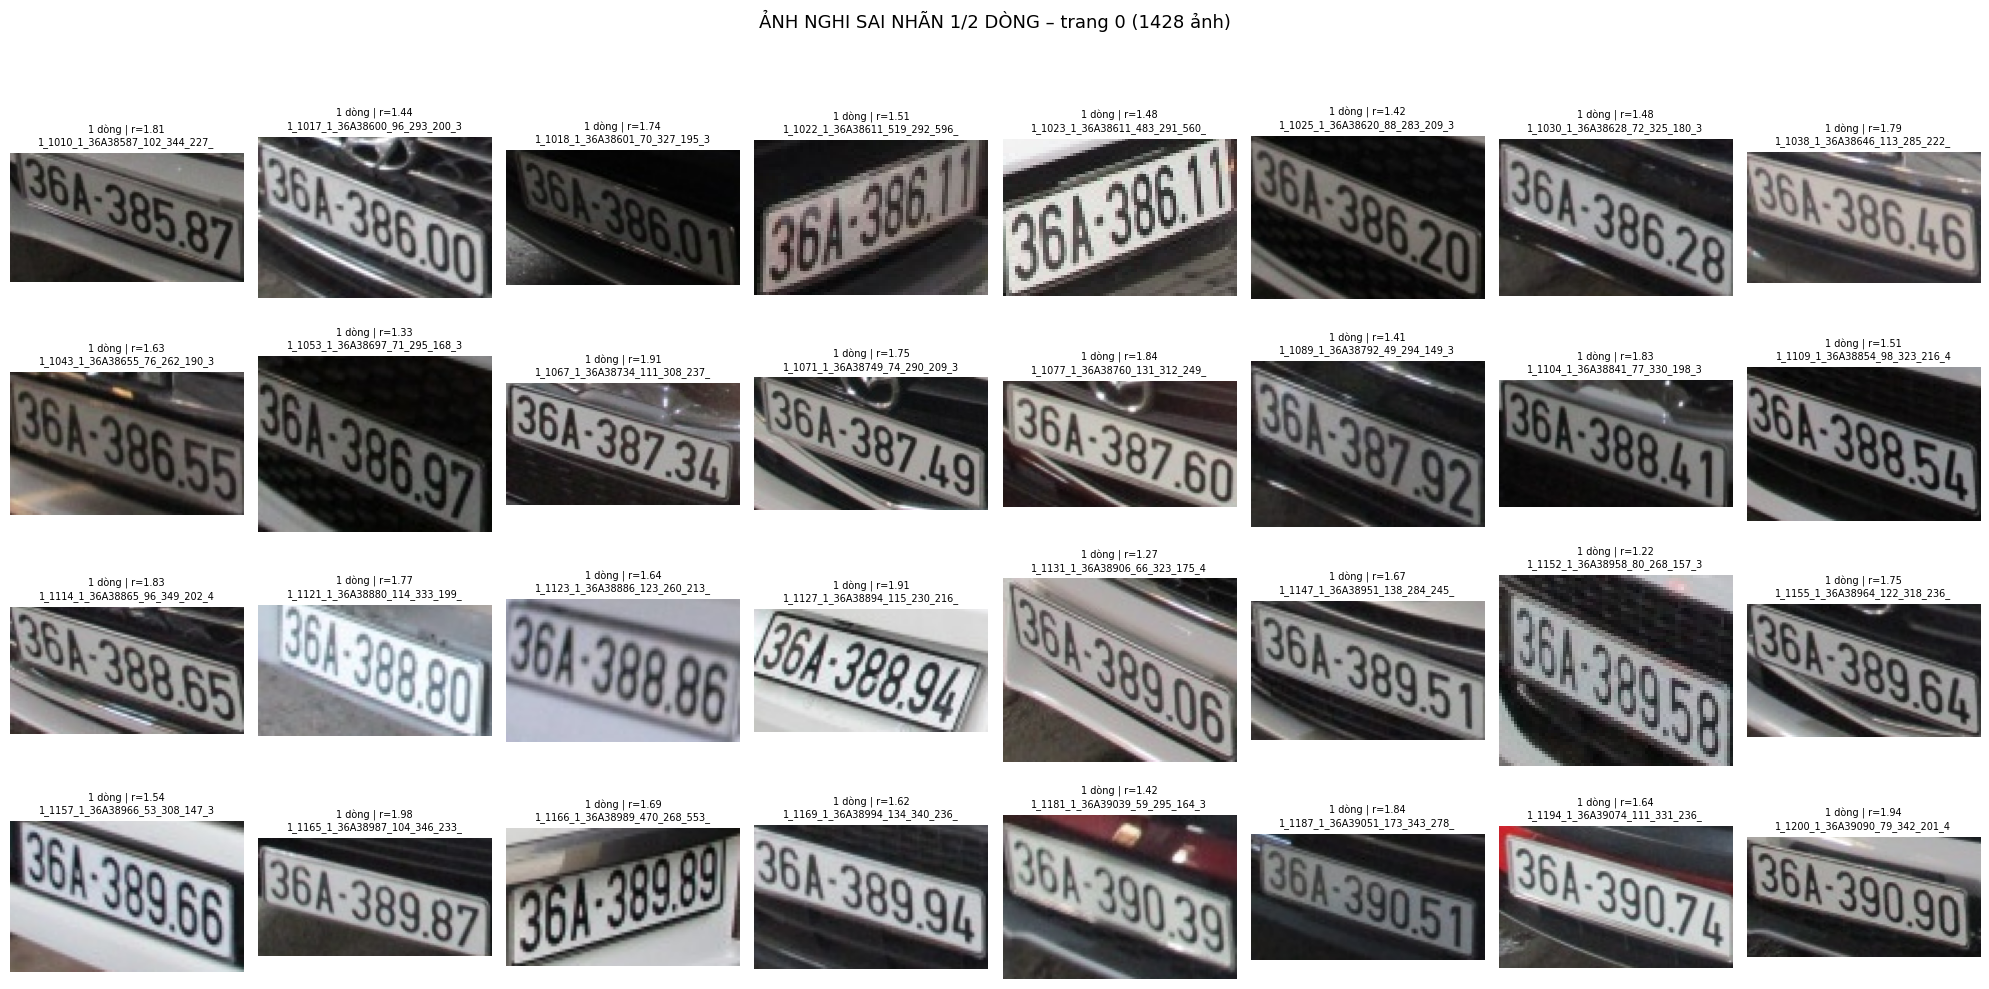

In [6]:
LAYOUT_REVIEW_PAGE, LAYOUT_REVIEW_PER_PAGE = 0, 32

def bbox_crop(img, s):
    if s["mode"] == "crop":
        return img
    h, w = img.shape[:2]
    xmin, ymin, xmax, ymax = s["bbox"]
    c = img[max(0, ymin):min(h, ymax), max(0, xmin):min(w, xmax)]
    return c if c.size else img

layout_suspects = [s for s in all_samples if s["input_ok"] and not s.get("layout_reviewed")
                   and ((s["is_two_rows"] and plate_ratio(s) >= 2.5) or (not s["is_two_rows"] and plate_ratio(s) <= 2.0))]
layout_suspects.sort(key=lambda s: os.path.basename(s["img_path"]))
with open(f"{SAVE_DIR}/layout_suspects.csv", "w", newline="", encoding="utf-8-sig") as f:
    wr = csv.writer(f)
    wr.writerow(["file", "layout", "label", "group", "current_layout", "ratio"])
    for s in layout_suspects:
        cur = "two_rows" if s["is_two_rows"] else "one_row"
        sug = "one_row" if s["is_two_rows"] else "two_rows"
        wr.writerow([os.path.basename(s["img_path"]), sug, s["label"], s["group"], cur, f"{plate_ratio(s):.2f}"])
print(f"-> {len(layout_suspects)} ảnh nghi sai nhãn 1/2 dòng: "
      + " | ".join(f"{g} = {sum(s['group'] == g for s in layout_suspects)}" for g in GROUPS))
print(f"   Danh sách: {SAVE_DIR}/layout_suspects.csv (cột 'layout' là layout ĐỀ XUẤT, chỉ chép dòng đã xác nhận sang layout_corrections.csv)")

page = layout_suspects[LAYOUT_REVIEW_PAGE * LAYOUT_REVIEW_PER_PAGE:(LAYOUT_REVIEW_PAGE + 1) * LAYOUT_REVIEW_PER_PAGE]
if page:
    rows = (len(page) + 7) // 8
    fig, axes = plt.subplots(rows, 8, figsize=(20, 2.6 * rows), squeeze=False)
    for a in axes.flat:
        a.axis("off")
    for a, s in zip(axes.flat, page):
        img = read_image(s["img_path"])
        a.imshow(cv2.cvtColor(bbox_crop(img, s), cv2.COLOR_BGR2RGB))
        a.set_title(f"{'2 dòng' if s['is_two_rows'] else '1 dòng'} | r={plate_ratio(s):.2f}\n{os.path.basename(s['img_path'])[:30]}", fontsize=7)
    fig.suptitle(f"ẢNH NGHI SAI NHÃN 1/2 DÒNG – trang {LAYOUT_REVIEW_PAGE} ({len(layout_suspects)} ảnh)", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
    plt.show()

### 5. Chia 3 Tập Train 70% / Val 15% / Test 15% Theo Nhóm Biển Số + Ảnh Trùng (Chống Data Leakage)
- Hai ảnh thuộc cùng một nhóm nếu **cùng chuỗi biển số** hoặc **giống hệt từng byte (cùng sha256)**, kể cả khi nhãn khác nhau. Mỗi nhóm chỉ nằm trong một tập.
- **Train** chỉ dùng mẫu sạch. **Val/Test giữ mọi mẫu**, kể cả bbox sai, ảnh hỏng, nhãn lạ, để số liệu báo cáo trung thực.

In [7]:
parent = list(range(len(all_samples)))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

first_seen = {}
for i, s in enumerate(all_samples):
    for key in (("label", s["label_orig"]), ("sha256", s["sha256"])):   # nhãn gốc: sửa nhãn tay không làm đổi split
        if key[1] is None:
            continue
        if key in first_seen:
            parent[find(i)] = find(first_seen[key])
        else:
            first_seen[key] = i

components = defaultdict(list)
for i, s in enumerate(all_samples):
    components[find(i)].append(s)
comp_list = sorted(components.values(), key=lambda ss: min((s["label_orig"], s["img_path"]) for s in ss))   # tái lập được
n_merged = sum(len({s["label_orig"] for s in ss}) > 1 for ss in comp_list)
print(f"-> {len(comp_list)} nhóm | {n_merged} nhóm gộp nhiều biển số khác nhau vì có ảnh trùng sha256")

order = np.random.RandomState(SEED).permutation(len(comp_list))
n_train = int(0.70 * len(comp_list))
n_val   = int(0.15 * len(comp_list))
parts = {"Train": order[:n_train], "Val": order[n_train:n_train + n_val], "Test": order[n_train + n_val:]}
split_all = {k: [s for j in sorted(v) for s in comp_list[j]] for k, v in parts.items()}
for k, ss in split_all.items():
    for s in ss:
        s["split"] = k

train_samples = [s for s in split_all["Train"] if s["drop"] == "OK"]
val_samples   = split_all["Val"]
test_samples  = split_all["Test"]

for key in ("label_orig", "sha256"):
    sets = {k: {s[key] for s in ss if s[key] is not None} for k, ss in split_all.items()}
    assert not (sets["Train"] & sets["Val"] or sets["Train"] & sets["Test"] or sets["Val"] & sets["Test"]), f"LỖI: trùng {key} giữa các tập!"

print("=" * 96)
print("PHÂN CHIA 3 TẬP HOÀN TẤT (THEO NHÓM BIỂN SỐ + ẢNH TRÙNG):")
print(f"{'Tập':8s}{'Ảnh':>8s}{'Biển số':>10s}" + "".join(f"{g:>14s}" for g in GROUPS) + f"{'không train':>14s}{'đầu vào lỗi':>14s}")
for name, ss in (("Train", train_samples), ("Val", val_samples), ("Test", test_samples)):
    print(f"{name:8s}{len(ss):8d}{len({s['label'] for s in ss}):10d}" + "".join(f"{sum(s['group'] == g for s in ss):14d}" for g in GROUPS)
          + f"{sum(s['drop'] != 'OK' for s in ss):14d}{sum(not s['input_ok'] for s in ss):14d}")
print(f"• Train đã bỏ {sum(s['drop'] != 'OK' for s in split_all['Train'])} mẫu không sạch. Biển số và sha256 không giao nhau giữa 3 tập.")
print("=" * 96)

# Dấu vân tay dữ liệu: resume chỉ được phép khi split + nhãn + tiền xử lý không đổi
DATA_FINGERPRINT = hashlib.sha256(json.dumps({
    "samples": sorted((s["split"], os.path.basename(s["img_path"]), s["label"], s["is_two_rows"], s["drop"]) for s in all_samples),
    "preprocess": [IMG_W, IMG_H, PAD_X, PAD_Y, SPLIT_METHOD, SPLIT_OVERLAP, EXIF_MODE],
    "chars": CHARS,
}).encode()).hexdigest()
print("-> Dấu vân tay dữ liệu:", DATA_FINGERPRINT[:16])

-> 20924 nhóm | 17 nhóm gộp nhiều biển số khác nhau vì có ảnh trùng sha256
PHÂN CHIA 3 TẬP HOÀN TẤT (THEO NHÓM BIỂN SỐ + ẢNH TRÙNG):
Tập          Ảnh   Biển số        1 dòng   2 dòng ô tô        xe máy   không train   đầu vào lỗi
Train      26079     14588         13328          8807          3944             0             0
Val         5510      3140          2826          1881           803             4             1
Test        5649      3142          2905          1918           826            13             0
• Train đã bỏ 59 mẫu không sạch. Biển số và sha256 không giao nhau giữa 3 tập.
-> Dấu vân tay dữ liệu: 601944a311558569


### 6. Tiền Xử Lý Ảnh (Đã Sửa Lỗi) & DataLoader
Quy trình cho mỗi mẫu:
1. Đọc ảnh theo pixel gốc.
2. Crop theo bbox, có đệm. Khi train, bbox được lệch ngẫu nhiên để mô phỏng YOLO.
3. *(train)* Xoay, nghiêng, phối cảnh nhẹ.
4. Biển 1 dòng: resize về **94×24**.
5. Biển 2 dòng (theo nhãn đã sửa):
   - **Tìm khe giữa 2 dòng chữ**: nhị phân hoá bằng adaptive threshold, thử các đường thẳng có tâm ở 30–70% chiều cao và độ nghiêng tới ±35% chiều cao, chọn đường **cắt qua ít nét mực nhất** (chỉ chấm điểm phần giữa ảnh, bỏ viền và ốc vít hai bên). Nếu một trong hai phía không có chữ hoặc khe không rõ thì gắn cờ **tách không chắc chắn** (vẫn dùng đường tốt nhất, không lùi về `h/2`).
   - **Nắn từng dòng thẳng lại** bằng `cv2.remap` theo đường tách (mỗi dòng lấn 3% qua đường tách), resize từng dòng về **94×24**, rồi ghép ngang thành **188×24**.
   - Khi train, khe được tìm lại **sau khi xoay/nghiêng ảnh**, nên mô hình học đúng cách tách sẽ gặp lúc suy luận.
6. *(train)* Augmentation sáng/tối, nhiễu, và **tối đa 1 phép làm suy giảm** (mờ / phân giải thấp / JPEG).
7. DataLoader **gom batch theo chiều rộng** (94 hoặc 188), thứ tự các batch được xáo.

Khi chạy pipeline YOLO thật, **phải dùng đúng hàm `preprocess` với `is_train=False`**, kể cả phần đệm bbox. Xem hàm `recognize_plate` ở Bước 15.

In [8]:
from torch.utils.data import Dataset, DataLoader, Sampler

def resize_to(img, size):
    w, h = size
    interp = cv2.INTER_AREA if (img.shape[1] > w or img.shape[0] > h) else cv2.INTER_LINEAR
    return cv2.resize(img, (w, h), interpolation=interp)

def crop_box(s, img_w, img_h, is_train=False):
    xmin, ymin, xmax, ymax = s["bbox"]
    bw, bh = xmax - xmin, ymax - ymin
    if is_train:   # lệch bbox ngẫu nhiên: hơi hụt hoặc hơi rộng như bbox của YOLO
        l, r = np.random.uniform(-0.02, 0.08, 2) * bw
        t, b = np.random.uniform(-0.04, 0.14, 2) * bh
    else:
        l = r = PAD_X * bw
        t = b = PAD_Y * bh
    x0, y0 = max(0, int(round(xmin - l))), max(0, int(round(ymin - t)))
    x1, y1 = min(img_w, int(round(xmax + r))), min(img_h, int(round(ymax + b)))
    return x0, y0, x1, y1

def get_plate_crop(img, s, is_train=False):
    if s["mode"] == "crop":
        return img
    h, w = img.shape[:2]
    x0, y0, x1, y1 = crop_box(s, w, h, is_train)
    crop = img[y0:y1, x0:x1]
    return crop if crop.size > 0 else img

def find_row_gap(crop):
    """Tìm đường thẳng (có thể nghiêng) giữa 2 dòng chữ, cắt qua ít nét mực nhất.
    Trả về (y ở mép trái, y ở mép phải) theo pixel của crop và cờ tin cậy."""
    h, w = crop.shape[:2]
    if h < 12 or w < 12:
        return (h / 2, h / 2), False
    sh = 96
    sw = min(256, max(64, round(w * sh / h)))
    gray = cv2.cvtColor(cv2.resize(crop, (sw, sh), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    ink = (cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 7) > 0).astype(np.float32)
    xs = np.arange(round(0.12 * sw), round(0.88 * sw))               # bỏ viền / ốc vít hai bên khi chấm điểm
    cc, dd = np.meshgrid(np.arange(round(0.30 * sh), round(0.70 * sh) + 1),
                         np.linspace(-0.35 * sh, 0.35 * sh, 15), indexing="ij")
    cc, dd = cc.ravel().astype(np.float32), dd.ravel().astype(np.float32)
    ys = cc[:, None] + dd[:, None] * (xs[None, :] / max(1, sw - 1) - 0.5)

    def line_ink(y):
        return np.mean([ink[np.clip(np.rint(y + band).astype(int), 0, sh - 1), xs[None, :]].mean(axis=1)
                        for band in (-1, 0, 1)], axis=0)

    gap = line_ink(ys)
    score = gap + 0.04 * np.abs(cc / sh - 0.5) + 0.003 * np.abs(dd) / (0.35 * sh)   # hơi ưu tiên giữa và ít nghiêng
    b = int(np.argmin(score))
    above = max(float(line_ink(ys[b:b + 1] - o * sh)[0]) for o in (0.12, 0.18, 0.24))
    below = max(float(line_ink(ys[b:b + 1] + o * sh)[0]) for o in (0.12, 0.18, 0.24))
    ok = min(above, below) > 0.03 and gap[b] / max(1e-6, min(above, below)) < 0.65   # 2 phía đều có chữ, khe rõ
    y_left, y_right = (cc[b] - dd[b] / 2) * h / sh, (cc[b] + dd[b] / 2) * h / sh
    return (float(np.clip(y_left, 2, h - 2)), float(np.clip(y_right, 2, h - 2))), bool(ok)

def row_strip(crop, y_top, y_bot):
    """Nắn dải giữa 2 đường y_top, y_bot (mỗi cột một giá trị) thành dải thẳng, rồi resize về 94x24."""
    w = crop.shape[1]
    out_h = max(2, int(round(float(np.mean(y_bot - y_top)))))
    t = np.linspace(0, 1, out_h, dtype=np.float32)[:, None]
    map_y = (y_top[None, :] + t * (y_bot - y_top)[None, :]).astype(np.float32)
    map_x = np.tile(np.arange(w, dtype=np.float32), (out_h, 1))
    strip = cv2.remap(crop, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return resize_to(strip, (IMG_W, IMG_H))

def row_cut(crop):
    h, w = crop.shape[:2]
    if SPLIT_METHOD == "sloped":
        (y_left, y_right), ok = find_row_gap(crop)
    else:
        (y_left, y_right), ok = (h / 2, h / 2), True
    return np.linspace(y_left, y_right, w, dtype=np.float32), ok

def split_two_rows(crop, overlap=SPLIT_OVERLAP):
    # mỗi dòng được nắn thẳng và resize riêng về 94x24 như một biển 1 dòng, rồi ghép ngang -> 188x24
    h, w = crop.shape[:2]
    cut, _ = row_cut(crop)
    ov = overlap * h
    top = row_strip(crop, np.zeros(w, np.float32), np.minimum(cut + ov, h - 1))
    bot = row_strip(crop, np.maximum(cut - ov, 0), np.full(w, h - 1, np.float32))
    return np.concatenate((top, bot), axis=1)

def geo_aug(crop, two_rows):
    h, w = crop.shape[:2]
    if h < 4 or w < 4:
        return crop
    if np.random.rand() < 0.5:
        max_angle = 6.0 if two_rows else 3.5     # biển dài xoay ít hơn để không cắt mất góc
        M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-max_angle, max_angle), np.random.uniform(0.95, 1.03))
        shear = np.random.uniform(-0.15, 0.15)
        M[0, 1] += shear
        M[0, 2] -= shear * h / 2
        crop = cv2.warpAffine(crop, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    if np.random.rand() < 0.3:
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        dst = src + (np.random.uniform(-0.04, 0.04, (4, 2)) * [w, h]).astype(np.float32)
        crop = cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REPLICATE)
    return crop

def degrade(x):
    """Đúng MỘT phép làm suy giảm chất lượng (không chồng nhiều phép như v2)."""
    h, w = x.shape[:2]
    kind = np.random.choice(["lowres", "blur", "motion", "jpeg"])
    if kind == "lowres":     # độ phân giải thấp (biển ở xa)
        f = np.random.uniform(0.6, 0.9)
        small = cv2.resize(x, (max(1, int(w * f)), max(1, int(h * f))), interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    if kind == "blur":
        return cv2.GaussianBlur(x, (3, 3), np.random.uniform(0.3, 0.8))
    if kind == "motion":     # nhòe chuyển động ngang
        k = np.zeros((3, 3), np.float32)
        k[1, :] = 1 / 3
        return cv2.filter2D(x, -1, k)
    ok, enc = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(np.random.uniform(40, 90))])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else x

def photo_aug(x0):
    x = x0.astype(np.float32)
    if np.random.rand() < 0.7:
        x = x * np.random.uniform(0.75, 1.25) + np.random.uniform(-25, 25)
    if np.random.rand() < 0.25:
        x = 255.0 * (np.clip(x, 0, 255) / 255.0) ** np.random.uniform(0.75, 1.35)
    if np.random.rand() < 0.1:
        x = np.repeat(x.mean(axis=2, keepdims=True), 3, axis=2)
    x = np.clip(x, 0, 255).astype(np.uint8)
    if np.random.rand() < 0.35:
        x = degrade(x)
    if np.random.rand() < 0.2:
        x = np.clip(x.astype(np.float32) + np.random.normal(0, np.random.uniform(2, 6), x.shape), 0, 255).astype(np.uint8)
    if x.std() < 0.5 * x0.std():   # mất quá nửa độ tương phản -> chữ khó đọc, dùng lại ảnh gốc
        return x0
    return x

def preprocess(img, s, is_train=False):
    """Ảnh BGR gốc + thông tin mẫu -> ảnh BGR uint8 24x94 (1 dòng) hoặc 24x188 (2 dòng) đưa vào LPRNet."""
    crop = get_plate_crop(img, s, is_train)
    if is_train:
        crop = geo_aug(crop, s["is_two_rows"])
    if s["is_two_rows"]:
        x = split_two_rows(crop)
    else:
        x = resize_to(crop, (IMG_W, IMG_H))
    if is_train:
        x = photo_aug(x)
    return x

def model_input(img, s, is_train=False):
    """Đầu vào mô hình cho một mẫu. Ảnh hỏng / bbox sai (chỉ có trong Val/Test) -> ảnh xám, dự đoán sẽ bị đặt rỗng."""
    if img is None or not s["input_ok"]:
        return np.full((IMG_H, input_width(s), 3), 127, np.uint8)
    return preprocess(img, s, is_train)

def to_tensor(x):
    x = (x.astype(np.float32) - 127.5) * 0.0078125
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class VNLPDataset(Dataset):
    def __init__(self, samples, is_train=False):
        self.samples = samples
        self.is_train = is_train

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        img = read_image(s["img_path"]) if s["input_ok"] else None
        x = to_tensor(model_input(img, s, self.is_train))
        # ký tự ngoài bảng chỉ có ở Val/Test (không tính loss), bỏ qua khi tạo target
        target = torch.tensor([CHARS_DICT[c] for c in s["label"] if c in CHARS_DICT], dtype=torch.long)
        return x, target, s["label"], i

def collate_fn(batch):
    imgs, targets, labels, idxs = zip(*batch)
    target_lengths = torch.tensor([len(t) for t in targets], dtype=torch.long)
    return torch.stack(imgs, 0), torch.cat(targets), target_lengths, labels, idxs

def worker_init_fn(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)

class WidthBatchSampler(Sampler):
    """Mỗi batch chỉ chứa ảnh cùng chiều rộng (94 hoặc 188).
    Khi train: lấy mẫu lặp có trọng số TRONG từng nhóm chiều rộng. Số mẫu mỗi nhóm cố định theo
    tổng trọng số, nên số batch mỗi epoch không đổi (OneCycleLR cần biết trước tổng số bước)."""
    def __init__(self, samples, batch_size, weights=None, shuffle=False, drop_last=False):
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        widths = np.array([input_width(s) for s in samples])
        w = np.ones(len(samples)) if weights is None else np.asarray(weights, dtype=np.float64)
        self.buckets = []
        for width in (IMG_W, IMG_W2):
            ids = np.flatnonzero(widths == width)
            if len(ids) == 0:
                continue
            n_draw = len(ids) if weights is None else int(round(len(samples) * w[ids].sum() / w.sum()))
            self.buckets.append((width, ids, w[ids] / w[ids].sum(), n_draw))
        self.weighted = weights is not None

    def _n_batches(self, n):
        return n // self.batch_size if self.drop_last else -(-n // self.batch_size)

    def __len__(self):
        return sum(self._n_batches(n) for _, _, _, n in self.buckets)

    def __iter__(self):
        batches = []
        for _, ids, p, n in self.buckets:
            order = np.random.choice(ids, n, replace=True, p=p) if self.weighted else ids
            for k in range(self._n_batches(n)):
                batches.append(order[k * self.batch_size:(k + 1) * self.batch_size].tolist())
        if self.shuffle:
            random.shuffle(batches)
        return iter(batches)

# Lấy mẫu lặp ảnh có chữ cái hiếm (K, X, G, Z, U...): A có ~11k mẫu nhưng Z chỉ ~100
train_letter_cnt = Counter(c for s in train_samples for c in s["label"] if c.isalpha())

def rare_weight(s):
    letters = [c for c in s["label"] if c.isalpha()]
    if not letters:
        return 1.0
    return float(np.clip(max(np.sqrt(RARE_REF / max(1, train_letter_cnt[c])) for c in letters), 1.0, RARE_MAX))

def sample_weight(s):
    return (MOTO_WEIGHT if s["group"] == "xe máy" else 1.0) * rare_weight(s)

def make_loader(samples, is_train):
    ds = VNLPDataset(samples, is_train)
    if is_train:
        weights = [sample_weight(s) for s in samples]
        bs = WidthBatchSampler(samples, BATCH_SIZE, weights, shuffle=True, drop_last=True)
    else:
        bs = WidthBatchSampler(samples, 256)
    return DataLoader(ds, batch_sampler=bs, collate_fn=collate_fn,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                      persistent_workers=NUM_WORKERS > 0, worker_init_fn=worker_init_fn)

train_loader = make_loader(train_samples, is_train=True)
val_loader   = make_loader(val_samples, is_train=False)
test_loader  = make_loader(test_samples, is_train=False)
print(f"-> DataLoaders: Train={len(train_loader)} batches | Val={len(val_loader)} batches | Test={len(test_loader)} batches")
for name, ld in (("Train", train_loader), ("Val", val_loader), ("Test", test_loader)):
    print(f"   {name:5s}: " + " | ".join(f"ảnh rộng {width}: {n} mẫu/epoch" for width, _, _, n in ld.batch_sampler.buckets))

# Số lần mỗi chữ cái được nhìn thấy trong 1 epoch: trước và sau khi lấy mẫu lặp (kỳ vọng)
w_all = np.array([sample_weight(s) for s in train_samples])
w_all = w_all * len(train_samples) / w_all.sum()
eff_cnt = Counter()
for s, wi in zip(train_samples, w_all):
    for c in s["label"]:
        if c.isalpha():
            eff_cnt[c] += wi
print("-> Chữ cái trong train (số lần gốc → kỳ vọng mỗi epoch sau lấy mẫu lặp):")
print("   " + " | ".join(f"{c}: {train_letter_cnt[c]}→{eff_cnt[c]:.0f}" for c, _ in sorted(train_letter_cnt.items(), key=lambda x: x[1])))

-> DataLoaders: Train=203 batches | Val=23 batches | Test=23 batches
   Train: ảnh rộng 94: 9310 mẫu/epoch | ảnh rộng 188: 16769 mẫu/epoch
   Val  : ảnh rộng 94: 2827 mẫu/epoch | ảnh rộng 188: 2683 mẫu/epoch
   Test : ảnh rộng 94: 2909 mẫu/epoch | ảnh rộng 188: 2740 mẫu/epoch
-> Chữ cái trong train (số lần gốc → kỳ vọng mỗi epoch sau lấy mẫu lặp):
   Z: 114→446 | U: 117→382 | S: 144→475 | V: 176→530 | P: 203→678 | Y: 220→681 | X: 221→630 | T: 223→637 | K: 245→734 | F: 285→711 | R: 286→441 | G: 342→956 | H: 410→839 | E: 444→893 | L: 625→863 | D: 644→786 | N: 891→822 | M: 1167→1085 | B: 2409→2156 | C: 5995→4114 | A: 11104→7486


#### 6.2 Cờ chất lượng cho từng ảnh
Các cờ dưới đây **không dùng để loại mẫu**, chỉ để in kết quả Test theo từng loại ảnh khó (Bước 13):
- `ảnh mờ`: phương sai Laplacian của crop < 15.
- `crop thấp`: crop cao dưới 16 px.
- `tách 2 dòng không chắc`: bộ tìm khe không tìm được khe rõ, hoặc một phía không có chữ.
- `nhãn lạ`: nhãn có ký tự ngoài bảng, sai định dạng VN, hoặc quá dài cho CTC.
- `đầu vào lỗi`: bbox sai hoặc ảnh không đọc được (chỉ có trong Val/Test).

In [9]:
def quality_info(s):
    if not s["input_ok"]:
        return None
    img = read_image(s["img_path"])
    if img is None:
        return None
    crop = get_plate_crop(img, s, is_train=False)
    blur = float(cv2.Laplacian(cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())
    gap_ok = row_cut(crop)[1] if s["is_two_rows"] else True
    return blur, crop.shape[0], gap_ok

audit_samples = train_samples + val_samples + test_samples
with ThreadPoolExecutor(max_workers=16) as ex:
    q_infos = list(ex.map(quality_info, audit_samples))

FLAG_NAMES = ["ảnh mờ", "crop thấp", "tách 2 dòng không chắc", "nhãn lạ", "đầu vào lỗi"]
for s, q in zip(audit_samples, q_infos):
    flags = []
    if q is None:
        flags.append("đầu vào lỗi")
    else:
        blur, crop_h, gap_ok = q
        s.update(blur=blur, crop_h=crop_h, gap_ok=gap_ok)
        if blur < 15:
            flags.append("ảnh mờ")
        if crop_h < 16:
            flags.append("crop thấp")
        if not gap_ok:
            flags.append("tách 2 dòng không chắc")
    if s["drop"] in ("nhãn có ký tự ngoài bảng", "nhãn quá dài cho CTC", "nhãn sai định dạng VN"):
        flags.append("nhãn lạ")
    s["flags"] = flags

print(f"SỐ ẢNH THEO CỜ CHẤT LƯỢNG (một ảnh có thể có nhiều cờ):")
print(f"{'Tập':7s}{'Nhóm':14s}{'n':>7s}" + "".join(f"{f:>24s}" for f in FLAG_NAMES))
for name, ss in (("Train", train_samples), ("Val", val_samples), ("Test", test_samples)):
    for g in GROUPS:
        sg = [s for s in ss if s["group"] == g]
        print(f"{name:7s}{g:14s}{len(sg):7d}" + "".join(f"{sum(f in s['flags'] for s in sg):24d}" for f in FLAG_NAMES))
two_ok = [s for s in audit_samples if s["is_two_rows"] and "gap_ok" in s]
if two_ok:
    print(f"-> Tách 2 dòng ({SPLIT_METHOD}): tìm được khe rõ ở {100 * np.mean([s['gap_ok'] for s in two_ok]):.1f}% ảnh 2 dòng")

SỐ ẢNH THEO CỜ CHẤT LƯỢNG (một ảnh có thể có nhiều cờ):
Tập    Nhóm                n                  ảnh mờ               crop thấp  tách 2 dòng không chắc                 nhãn lạ             đầu vào lỗi
Train  1 dòng          13328                       1                       0                       0                       0                       0
Train  2 dòng ô tô      8807                       0                       0                      45                       0                       0
Train  xe máy           3944                       0                       0                      11                       0                       0
Val    1 dòng           2826                       0                       0                       0                       2                       1
Val    2 dòng ô tô      1881                       0                       0                      10                       1                       0
Val    xe máy            803                      

### 7. Kiểm Tra Trực Quan Tiền Xử Lý (BẮT BUỘC XEM TRƯỚC KHI TRAIN)
- Cột 1 là ảnh gốc. **Khung xanh lá** là bbox nhãn, **khung vàng** là vùng cắt thật (đã đệm).
- Cột 2 là đầu vào khi đánh giá/suy luận. Cột 3, 4 là đầu vào khi train (đã augmentation).

**Đúng** là cột 2 chứa trọn biển số. Riêng biển 2 dòng thì phải thấy *dòng trên* và *dòng dưới* nằm cạnh nhau. Nếu thấy lưới tản nhiệt, mặt đường hay biển bị cắt mất chữ thì **dừng lại, đừng train**.

In [10]:
def bgr2rgb(x):
    return cv2.cvtColor(x, cv2.COLOR_BGR2RGB)

def add_title(fig, title):
    # chừa chỗ phía trên để tiêu đề chung không đè lên tiêu đề của hàng đầu tiên
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))

def full_with_boxes(s, img=None):
    img = read_image(s["img_path"]) if img is None else img
    if img is None:
        return np.zeros((48, 188, 3), np.uint8)
    vis = img.copy()
    if s["mode"] == "full":
        h, w = img.shape[:2]
        xmin, ymin, xmax, ymax = s["bbox"]
        x0, y0, x1, y1 = crop_box(s, w, h, is_train=False)
        t = max(2, w // 200)
        cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 255), t)        # vàng: vùng cắt thật
        cv2.rectangle(vis, (xmin, ymin), (xmax, ymax), (0, 255, 0), t)  # xanh lá: bbox nhãn
    return bgr2rgb(vis)

def preview_samples(samples, title, n=6, n_aug=2, seed=0):
    samples = [s for s in samples if s["input_ok"]]
    if not samples:
        print(f"(Không có mẫu nào: {title})")
        return
    picks = random.Random(seed).sample(samples, min(n, len(samples)))
    cols = 2 + n_aug
    fig, axes = plt.subplots(len(picks), cols, figsize=(4.2 * cols, 2.0 * len(picks)), squeeze=False)
    for r, s in enumerate(picks):
        img = read_image(s["img_path"])
        axes[r, 0].imshow(full_with_boxes(s, img))
        axes[r, 0].set_title(f"{s['group']} | {s['mode']} | {img.shape[1]}x{img.shape[0]} | EXIF={s['exif']}", fontsize=8)
        axes[r, 1].imshow(bgr2rgb(preprocess(img, s, is_train=False)))
        axes[r, 1].set_title(f"INPUT val/test: {s['label']}", fontsize=9)
        for k in range(n_aug):
            axes[r, 2 + k].imshow(bgr2rgb(preprocess(img, s, is_train=True)))
            axes[r, 2 + k].set_title(f"INPUT train aug #{k + 1}", fontsize=9)
        for a in axes[r]:
            a.axis("off")
    add_title(fig, title)
    plt.show()

for g in GROUPS:
    preview_samples([s for s in train_samples if s["group"] == g], f"KIỂM TRA TIỀN XỬ LÝ – {g}")
preview_samples([s for s in clean_samples if old_pipeline_broken(s)], "CÁC MẪU TỪNG BỊ HỎNG Ở BẢN CŨ – bây giờ phải đọc được biển")
preview_samples([s for s in clean_samples if s["exif"] in EXIF_ROTATED], "ẢNH CÓ CỜ XOAY EXIF – kiểm tra khung xanh có trùng biển không")
preview_samples([s for s in clean_samples if s["mode"] == "crop"], "ẢNH ĐÃ CẮT SẴN (mode = crop)")

Output hidden; open in https://colab.research.google.com to view.

#### 7.1 Kiểm tra đường tách biển 2 dòng
- Cột 1 là crop. **Đường đỏ** là đường tách tìm được, **2 đường vàng** là giới hạn lấn (mỗi dòng lấn 3% qua đường tách).
- Cột 2 là đầu vào mô hình (188×24), cột 3 là cách cắt ngang ở `h/2` của v3 để so sánh.

**Đúng** là đường đỏ chạy trong khe giữa 2 dòng chữ, kể cả khi biển nghiêng, và cột 2 không bị mất đầu/chân chữ. Hàng "tách không chắc" là các ca khó: nếu phần lớn trong số đó cắt sai thì báo lại, đừng train.

In [11]:
def draw_cut(crop):
    vis = crop.copy()
    h, w = crop.shape[:2]
    cut, ok = row_cut(crop)
    t = max(1, h // 60)
    for dy, color in ((0, (0, 0, 255) if ok else (255, 0, 255)), (SPLIT_OVERLAP * h, (0, 255, 255)), (-SPLIT_OVERLAP * h, (0, 255, 255))):
        cv2.line(vis, (0, int(round(cut[0] + dy))), (w - 1, int(round(cut[-1] + dy))), color, t)
    return vis, ok

def horizontal_split(crop):
    h = crop.shape[0]
    top = crop[:max(1, int(round(h * (0.5 + SPLIT_OVERLAP))))]
    bot = crop[min(h - 1, int(round(h * (0.5 - SPLIT_OVERLAP)))):]
    return np.concatenate((resize_to(top, (IMG_W, IMG_H)), resize_to(bot, (IMG_W, IMG_H))), axis=1)

def preview_row_splits(samples, title, n=8, seed=0):
    samples = [s for s in samples if s["input_ok"]]
    if not samples:
        print(f"(Không có mẫu nào: {title})")
        return
    picks = random.Random(seed).sample(samples, min(n, len(samples)))
    fig, axes = plt.subplots(len(picks), 3, figsize=(14, 1.9 * len(picks)), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 2, 2]})
    for r, s in enumerate(picks):
        img = read_image(s["img_path"])
        crop = get_plate_crop(img, s, is_train=False)
        vis, ok = draw_cut(crop)
        axes[r, 0].imshow(bgr2rgb(vis))
        axes[r, 0].set_title(f"{s['group']} | {'khe rõ' if ok else 'KHÔNG CHẮC'}", fontsize=8)
        axes[r, 1].imshow(bgr2rgb(preprocess(img, s, is_train=False)))
        axes[r, 1].set_title(f"v4 ({SPLIT_METHOD}): {s['label']}", fontsize=9)
        axes[r, 2].imshow(bgr2rgb(horizontal_split(crop)))
        axes[r, 2].set_title("v3 (cắt ngang h/2)", fontsize=9)
        for a in axes[r]:
            a.axis("off")
    add_title(fig, title)
    plt.show()

for g in ("xe máy", "2 dòng ô tô"):
    preview_row_splits([s for s in train_samples if s["group"] == g and s["is_two_rows"]], f"ĐƯỜNG TÁCH 2 DÒNG – {g}")
preview_row_splits([s for s in audit_samples if s.get("gap_ok") is False], "ĐƯỜNG TÁCH 2 DÒNG – các ca TÁCH KHÔNG CHẮC")
preview_samples([s for s in all_samples if s["is_two_rows"] != s["layout_label"]], "ẢNH ĐÃ SỬA NHÃN 1/2 DÒNG – đầu vào phải đúng kiểu biển")

Output hidden; open in https://colab.research.google.com to view.

#### 7.2 Kiểm tra một batch thật & quét toàn bộ Val/Test
Ô này quét toàn bộ Val/Test và tìm ảnh đầu vào gần như trơn (độ lệch chuẩn thấp), là dấu hiệu crop trượt khỏi biển số. **Notebook tự dừng nếu có hơn 1% ảnh như vậy.** Ảnh xám cố ý của các mẫu "đầu vào lỗi" không bị tính vào đây.

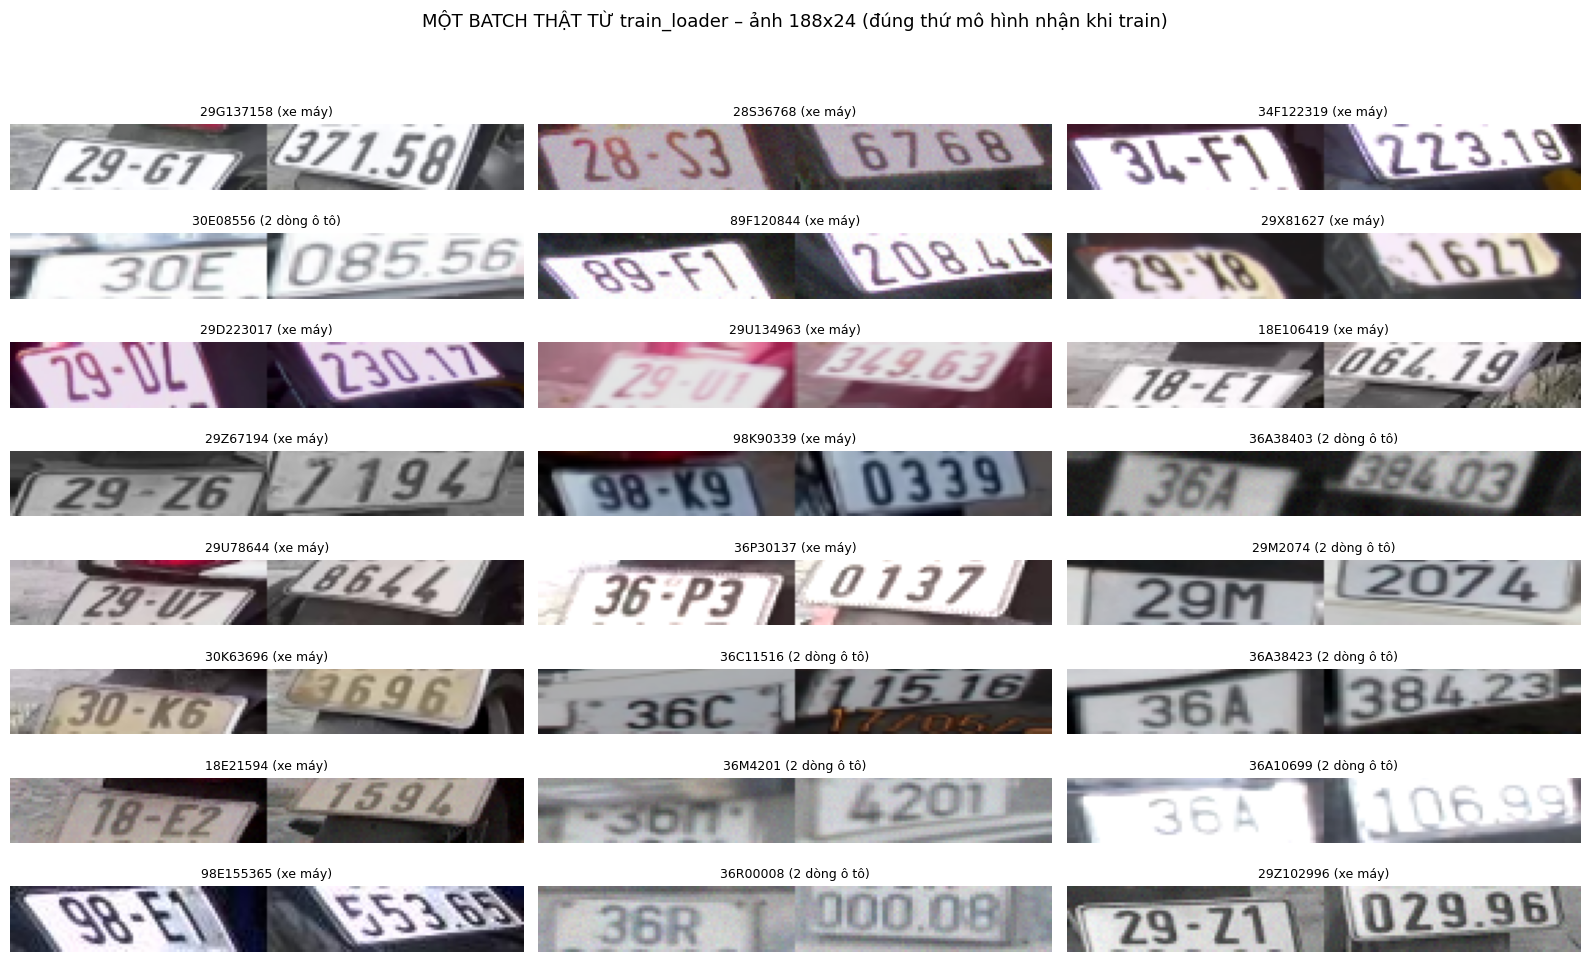

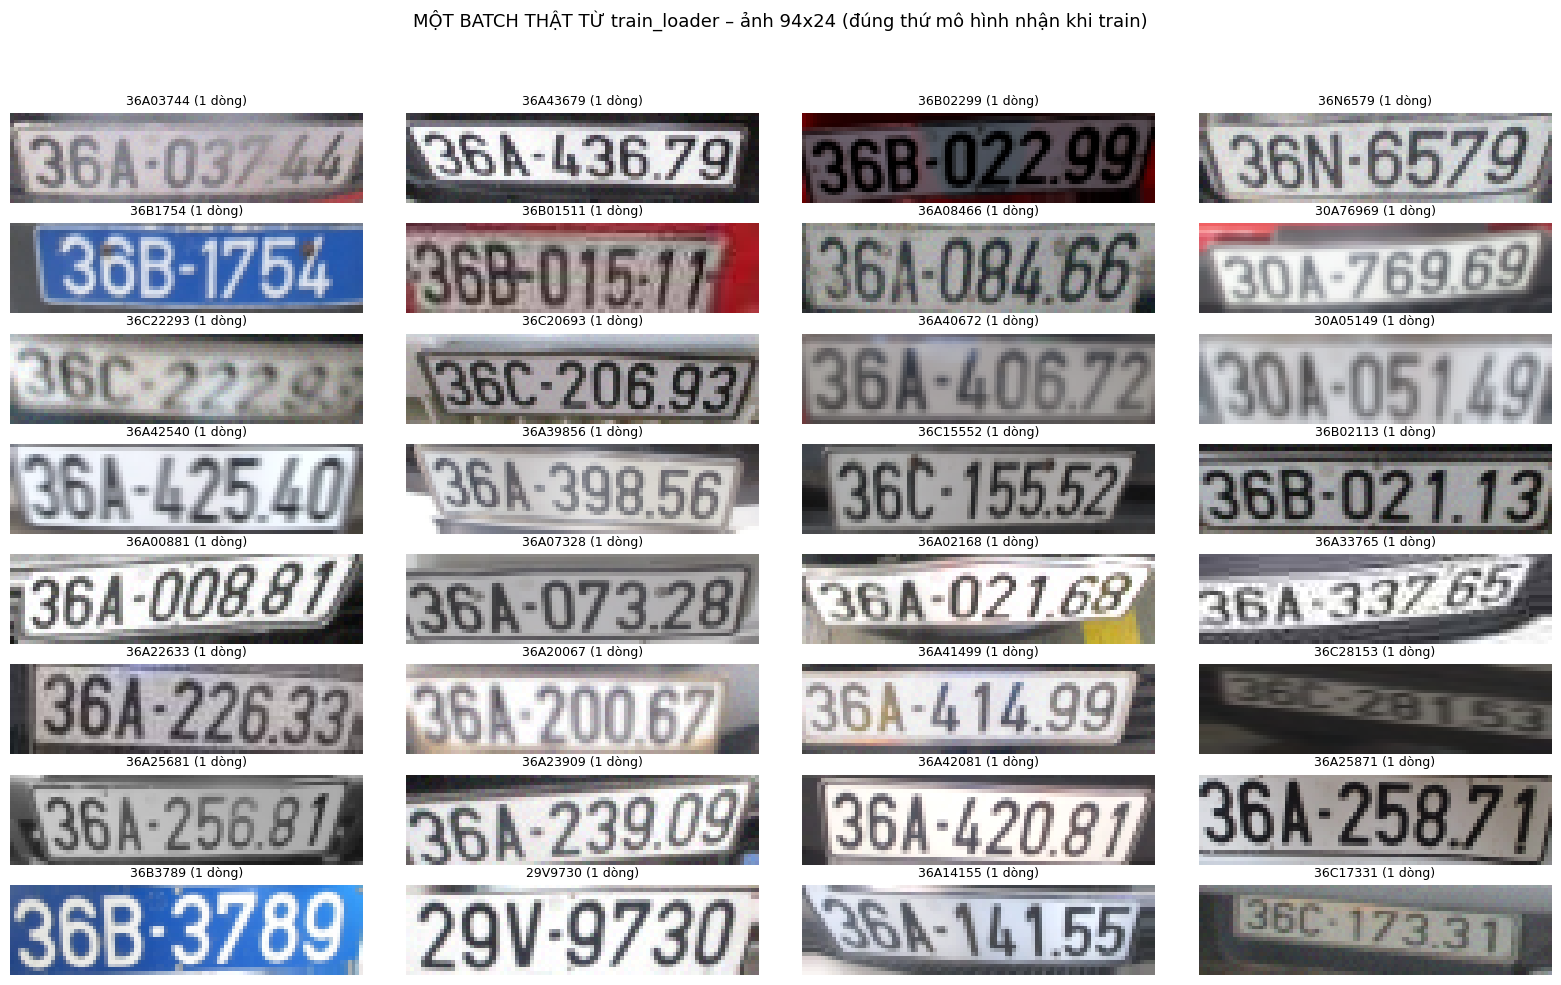

-> Val: 5510 ảnh (2827 ảnh 3x24x94, 2683 ảnh 3x24x188), đúng kích thước theo loại biển | ảnh gần như trơn: 1 (0.02%)
-> Test: 5649 ảnh (2909 ảnh 3x24x94, 2740 ảnh 3x24x188), đúng kích thước theo loại biển | ảnh gần như trơn: 0 (0.00%)


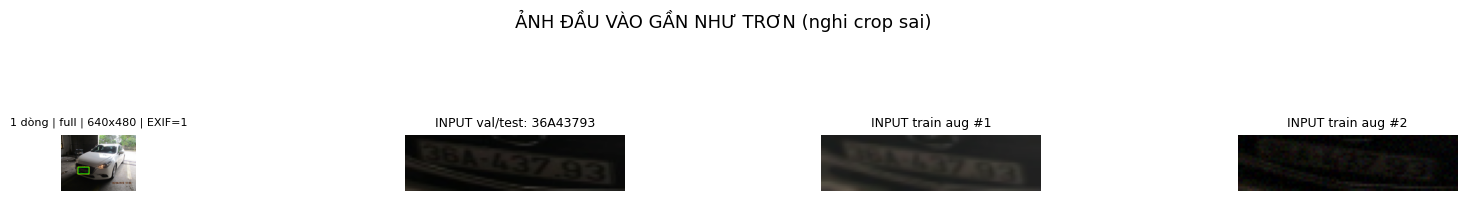

-> TIỀN XỬ LÝ ĐẠT YÊU CẦU, có thể bắt đầu huấn luyện.


In [12]:
def tensor_to_bgr(t):
    return np.clip(t.numpy().transpose(1, 2, 0) / 0.0078125 + 127.5, 0, 255).astype(np.uint8)

shown = set()
for imgs, _, _, labels, idxs in train_loader:   # in 1 batch ảnh 94 và 1 batch ảnh 188
    width = imgs.shape[-1]
    if width in shown:
        continue
    shown.add(width)
    cols = 4 if width == IMG_W else 3
    fig, axes = plt.subplots(8, cols, figsize=(16, 10), squeeze=False)
    for k, a in enumerate(axes.flat):
        a.axis("off")
        if k < len(labels):
            a.imshow(bgr2rgb(tensor_to_bgr(imgs[k])))
            a.set_title(f"{labels[k]} ({train_samples[idxs[k]]['group']})", fontsize=9)
    add_title(fig, f"MỘT BATCH THẬT TỪ train_loader – ảnh {width}x{IMG_H} (đúng thứ mô hình nhận khi train)")
    plt.show()
    if len(shown) == 2:
        break

def scan_loader(loader, samples, name, std_thr=0.08):
    n, flat, n_w = 0, [], Counter()
    for imgs, _, _, labels, idxs in loader:
        widths = {input_width(samples[i]) for i in idxs}
        assert len(widths) == 1, "Một batch chứa ảnh khác chiều rộng"
        assert imgs.shape[1:] == (3, IMG_H, widths.pop()), f"Sai kích thước đầu vào: {tuple(imgs.shape)}"
        assert torch.isfinite(imgs).all(), "Đầu vào có NaN/Inf"
        n += len(labels)
        n_w[imgs.shape[-1]] += len(labels)
        stds = imgs.flatten(1).std(1).tolist()
        flat += [samples[i] for i, sd in zip(idxs, stds) if sd < std_thr and samples[i]["input_ok"]]
    w_str = ", ".join(f"{c} ảnh 3x{IMG_H}x{w}" for w, c in sorted(n_w.items()))
    print(f"-> {name}: {n} ảnh ({w_str}), đúng kích thước theo loại biển | ảnh gần như trơn: {len(flat)} ({100 * len(flat) / max(1, n):.2f}%)")
    return n, flat

n_val, flat_val = scan_loader(val_loader, val_samples, "Val")
n_test, flat_test = scan_loader(test_loader, test_samples, "Test")
flat_all = flat_val + flat_test
preview_samples(flat_all, "ẢNH ĐẦU VÀO GẦN NHƯ TRƠN (nghi crop sai)", n=8)
if len(flat_all) > 0.01 * (n_val + n_test):
    raise RuntimeError("Hơn 1% ảnh đầu vào bị trơn. Hãy xem hình phía trên và sửa tiền xử lý trước khi train!")
print("-> TIỀN XỬ LÝ ĐẠT YÊU CẦU, có thể bắt đầu huấn luyện.")

### 8. Tải Trọng Số Pre-trained Gốc Của Tác Giả (sirius-ai)

In [13]:
if not os.path.exists(AUTHOR_WEIGHTS):
    print("Đang tải Final_LPRNet_model.pth chính thức...")
    !git clone -q --depth 1 https://github.com/sirius-ai/LPRNet_Pytorch.git /content/LPRNet_Pytorch
    shutil.copy("/content/LPRNet_Pytorch/weights/Final_LPRNet_model.pth", AUTHOR_WEIGHTS)
print(f"-> Trọng số tác giả: {AUTHOR_WEIGHTS} ({os.path.getsize(AUTHOR_WEIGHTS) / 1e6:.2f} MB)")

if WEIGHTS_MODE == "resume":
    if os.path.exists(LAST_PATH):
        print(f"-> ĐÃ CHỌN: TRAIN TIẾP từ {LAST_PATH}")
    else:
        raise FileNotFoundError(f"Chưa có {LAST_PATH}. Hãy đặt WEIGHTS_MODE = 'author' để train từ đầu.")
elif WEIGHTS_MODE == "prev":
    if not os.path.exists(PREV_BEST_PATH):
        raise FileNotFoundError(f"Chưa có {PREV_BEST_PATH}. Hãy đặt WEIGHTS_MODE = 'author'.")
    print(f"-> ĐÃ CHỌN: KHỞI TẠO TỪ CHECKPOINT BẢN TRƯỚC ({PREV_BEST_PATH})")
else:
    print("-> ĐÃ CHỌN: TRANSFER LEARNING TỪ TRỌNG SỐ TÁC GIẢ.")

-> Trọng số tác giả: /content/weights/Final_LPRNet_model.pth (1.81 MB)
-> ĐÃ CHỌN: TRANSFER LEARNING TỪ TRỌNG SỐ TÁC GIẢ.


### 9. Kiến Trúc LPRNet Gốc (Zherzdev & Gruzdev, 2018; bản PyTorch sirius-ai) & Chuyển Giao 100% Trọng Số
- Kiến trúc giữ **đúng từng tầng** như bản gốc, nên tên và kích thước tensor khớp 100% với `Final_LPRNet_model.pth`.
- **Global Context:** đặc trưng ở các tầng 2, 6, 13, 22 được pooling về cùng kích thước 4×T, chuẩn hóa, ghép kênh rồi qua conv 1×1.
- **BatchNorm theo chiều rộng (v4):** mỗi batch chỉ chứa một loại chiều rộng, nên các tầng BatchNorm giữ **2 bộ thống kê chạy riêng** (ảnh 94 và ảnh 188), còn gamma/beta và mọi trọng số khác vẫn dùng chung. Sanity check cho thấy dùng chung 1 bộ thống kê thì đúng 100% khi train nhưng chỉ ~56% khi chuyển sang chế độ đánh giá. Khi transfer, bộ thống kê cho ảnh 188 được khởi tạo bằng bản sao thống kê gốc.
- **Ảnh rộng 188 (biển 2 dòng):** toàn bộ backbone là tích chập nên chạy được với mọi chiều rộng. Riêng 3 nhánh Global Context vẫn dùng avgpool gốc (cùng kích thước cửa sổ), sau đó được nội suy theo chiều ngang về đúng T = 42. Với ảnh 94 không cần nội suy (T = 18), nên mô hình **giống hệt bản gốc** và transfer vẫn đúng 100%.
- Bản gốc chuẩn hóa global context bằng trung bình trên **cả batch**. Ở đây chuẩn hóa **theo từng ảnh** để kết quả không phụ thuộc batch size (khi suy luận batch = 1).
- **Chuyển giao tầng phân loại theo ký tự:** mô hình gốc có 68 lớp (31 chữ Hán, 0–9, A–Z, blank `-`). 3 tensor phụ thuộc số lớp (`backbone.20`, `backbone.21`, `container.0`) được **lấy đúng các hàng/cột của 30 ký tự VN và blank**. Nhờ vậy cả tầng phân loại cũng được kế thừa, không phải khởi tạo ngẫu nhiên.

In [14]:
SIRIUS_CHARS = [
    '京', '沪', '津', '渝', '冀', '晋', '蒙', '辽', '吉', '黑',
    '苏', '浙', '皖', '闽', '赣', '鲁', '豫', '鄂', '湘', '粤',
    '桂', '琼', '川', '贵', '云', '藏', '陕', '甘', '青', '宁',
    '新',
    '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K',
    'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'U', 'V',
    'W', 'X', 'Y', 'Z', 'I', 'O', '-'
]

class small_basic_block(nn.Module):
    def __init__(self, ch_in, ch_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(ch_in, ch_out // 4, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out // 4, kernel_size=(3, 1), padding=(1, 0)),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out // 4, kernel_size=(1, 3), padding=(0, 1)),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out, kernel_size=1),
        )

    def forward(self, x):
        return self.block(x)

class WidthBatchNorm2d(nn.BatchNorm2d):
    """BatchNorm dùng chung gamma/beta nhưng giữ thống kê chạy (running mean/var) RIÊNG cho ảnh rộng 94
    (biển 1 dòng) và ảnh rộng 188 (biển 2 dòng). Mỗi batch chỉ có một loại chiều rộng, nên nếu dùng chung
    một bộ thống kê thì lúc đánh giá cả hai loại ảnh đều bị chuẩn hoá lệch."""
    def __init__(self, num_features):
        super().__init__(num_features)
        self.register_buffer("running_mean_wide", torch.zeros(num_features))
        self.register_buffer("running_var_wide", torch.ones(num_features))
        self.wide = False

    def forward(self, x):
        if not self.wide:
            return super().forward(x)
        base_mean, base_var = self.running_mean, self.running_var
        self.running_mean, self.running_var = self.running_mean_wide, self.running_var_wide
        try:
            return super().forward(x)   # cập nhật tại chỗ bộ thống kê "wide"
        finally:
            self.running_mean_wide, self.running_var_wide = self.running_mean, self.running_var
            self.running_mean, self.running_var = base_mean, base_var

def fill_wide_stats(sd):
    """Checkpoint chưa có thống kê riêng cho ảnh 188 (trọng số tác giả, v2, v3): khởi tạo bằng bản sao thống kê chung."""
    sd = dict(sd)
    for k in list(sd):
        if k.endswith(("running_mean", "running_var")) and k + "_wide" not in sd:
            sd[k + "_wide"] = sd[k].clone()
    return sd

class LPRNet(nn.Module):
    KEEP_IDX = (2, 6, 13, 22)   # các tầng lấy đặc trưng cho Global Context

    def __init__(self, class_num=NUM_CLASSES, dropout_rate=0.5):
        super().__init__()
        self.class_num = class_num
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1),                       # 0
            WidthBatchNorm2d(64),
            nn.ReLU(),                                                       # 2  *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 1, 1)),
            small_basic_block(64, 128),                                      # 4
            WidthBatchNorm2d(128),
            nn.ReLU(),                                                       # 6  *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(2, 1, 2)),
            small_basic_block(64, 256),                                      # 8
            WidthBatchNorm2d(256),
            nn.ReLU(),                                                       # 10
            small_basic_block(256, 256),                                     # 11
            WidthBatchNorm2d(256),
            nn.ReLU(),                                                       # 13 *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(4, 1, 2)),
            nn.Dropout(dropout_rate),
            nn.Conv2d(64, 256, kernel_size=(1, 4), stride=1),                # 16
            WidthBatchNorm2d(256),
            nn.ReLU(),                                                       # 18
            nn.Dropout(dropout_rate),
            nn.Conv2d(256, class_num, kernel_size=(13, 1), stride=1),        # 20
            WidthBatchNorm2d(class_num),
            nn.ReLU(),                                                       # 22 *
        )
        self.container = nn.Sequential(
            nn.Conv2d(448 + class_num, class_num, kernel_size=(1, 1), stride=(1, 1)),
        )

    def forward(self, x):
        wide = x.shape[-1] != IMG_W
        for m in self.modules():
            if isinstance(m, WidthBatchNorm2d):
                m.wide = wide
        keep = []
        for i, layer in enumerate(self.backbone.children()):
            x = layer(x)
            if i in self.KEEP_IDX:
                keep.append(x)
        out_hw = keep[-1].shape[-2:]   # (4, T): T = 18 với ảnh rộng 94, T = 42 với ảnh rộng 188
        context = []
        for i, f in enumerate(keep):
            if i in (0, 1):
                f = F.avg_pool2d(f, kernel_size=5, stride=5)
            elif i == 2:
                f = F.avg_pool2d(f, kernel_size=(4, 10), stride=(4, 2))
            if f.shape[-2:] != out_hw:   # chỉ xảy ra khi ảnh khác rộng 94
                f = F.interpolate(f, size=out_hw, mode="bilinear", align_corners=False)
            f = f / f.pow(2).mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)
            context.append(f)
        x = self.container(torch.cat(context, 1))
        logits = x.mean(dim=2)            # [B, C, T]
        return logits.permute(2, 0, 1)    # [T, B, C] cho CTC

HEAD_PREFIXES = ("backbone.20.", "backbone.21.", "container.")   # các tensor phụ thuộc số lớp
CTX_CH = 64 + 128 + 256

def read_state_dict(path):
    sd = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(sd, dict) and isinstance(sd.get("model"), dict):   # checkpoint "last" (có optimizer, history...)
        sd = sd["model"]
    return {k.replace("module.", ""): v for k, v in sd.items()}

def remap_classes(sd, src_chars, src_blank, base=None):
    """Cắt / ghép 3 tầng phụ thuộc số lớp theo ký tự, từ bảng src_chars sang CHARS + blank.
    Ký tự không có trong src_chars (vd. R với checkpoint v4) lấy từ base (state dict đã theo bảng mới)."""
    n_src = sd["container.0.weight"].shape[0]
    new_ids, src_ids = [], []
    for j, c in enumerate(CHARS + [None]):
        si = src_blank if c is None else (src_chars.index(c) if c in src_chars else None)
        if si is not None:
            new_ids.append(j); src_ids.append(si)
    missing = [c for c in CHARS if c not in src_chars]
    assert base is not None or not missing, f"Thiếu ký tự {missing} và không có trọng số nền"
    hi, si = torch.tensor(new_ids), torch.tensor(src_ids)
    out = {}
    for k, v in sd.items():
        if not (k.startswith(HEAD_PREFIXES) and v.ndim >= 1 and v.shape[0] == n_src):
            out[k] = v
            continue
        if base is None:
            new = torch.zeros((NUM_CLASSES,) + v.shape[1:] if k != "container.0.weight" else (NUM_CLASSES, CTX_CH + NUM_CLASSES) + v.shape[2:], dtype=v.dtype)
        else:
            new = base[k].clone()
        if k == "container.0.weight":   # [n_src, 448 + n_src, 1, 1] -> [C, 448 + C, 1, 1]
            cols_new = torch.cat([torch.arange(CTX_CH), CTX_CH + hi])
            cols_src = torch.cat([torch.arange(CTX_CH), CTX_CH + si])
            new[hi[:, None], cols_new[None, :]] = v[si[:, None], cols_src[None, :]]
        else:
            new[hi] = v[si]
        out[k] = new
    return out, missing

def author_state(path=AUTHOR_WEIGHTS):
    sd = read_state_dict(path)
    assert sd["container.0.weight"].shape[0] == len(SIRIUS_CHARS), "File tác giả có số lớp khác 68"
    sd, _ = remap_classes(sd, SIRIUS_CHARS, SIRIUS_CHARS.index("-"))
    return fill_wide_stats(sd)

def load_any_checkpoint(path):
    """Nạp checkpoint v2/v3/v4 (31 lớp, chưa có R) hoặc v5 (32 lớp) theo bảng ký tự hiện tại."""
    sd = read_state_dict(path)
    n = sd["container.0.weight"].shape[0]
    if n == NUM_CLASSES:
        return fill_wide_stats(sd)
    assert n == len(V4_CHARS) + 1, f"Checkpoint có {n} lớp, không rõ bảng ký tự"
    sd, missing = remap_classes(fill_wide_stats(sd), V4_CHARS, len(V4_CHARS), base=author_state())
    print(f"   checkpoint {n} lớp -> {NUM_CLASSES} lớp; ký tự mới {missing} lấy từ trọng số tác giả")
    return sd

def transfer_author_weights(model, path):
    sd = author_state(path)
    n_author = sum(not k.endswith("_wide") for k in sd)
    model.load_state_dict(sd, strict=True)
    print(f"-> ĐÃ CHUYỂN GIAO {n_author}/{n_author} TENSOR (100%) TỪ FILE TÁC GIẢ "
          f"(+ {len(sd) - n_author} bản sao thống kê BatchNorm cho ảnh rộng 188)")
    print(f"   Tầng phân loại: lấy {NUM_CLASSES} / {len(SIRIUS_CHARS)} lớp gốc theo ký tự ({len(CHARS)} ký tự VN + blank)")

model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
if WEIGHTS_MODE == "author":
    transfer_author_weights(model, AUTHOR_WEIGHTS)
elif WEIGHTS_MODE == "prev":
    model.load_state_dict(load_any_checkpoint(PREV_BEST_PATH))
    print(f"-> ĐÃ NẠP CHECKPOINT BẢN TRƯỚC: {PREV_BEST_PATH}")

model.eval()
with torch.no_grad():
    for w in (IMG_W, IMG_W2):
        out = model(torch.zeros(2, 3, IMG_H, w, device=device))
        assert out.shape == (T_STEPS[w], 2, NUM_CLASSES), f"Đầu ra sai kích thước: {tuple(out.shape)}"
        print(f"-> Ảnh {w}x{IMG_H}: đầu ra (T, B, C) = {tuple(out.shape)}")
print(f"-> Số tham số: {sum(p.numel() for p in model.parameters()) / 1e3:.1f}K")

-> ĐÃ CHUYỂN GIAO 62/62 TENSOR (100%) TỪ FILE TÁC GIẢ (+ 12 bản sao thống kê BatchNorm cho ảnh rộng 188)
   Tầng phân loại: lấy 32 / 68 lớp gốc theo ký tự (31 ký tự VN + blank)
-> Ảnh 94x24: đầu ra (T, B, C) = (18, 2, 32)
-> Ảnh 188x24: đầu ra (T, B, C) = (42, 2, 32)
-> Số tham số: 307.3K


### 10. Giải Mã CTC, Hậu Xử Lý Định Dạng Biển VN & Đánh Giá Theo Từng Nhóm
**Giải mã có ràng buộc định dạng (mới ở v5):** thay vì lấy ký tự xác suất cao nhất ở từng bước (greedy), beam search CTC chỉ giữ các chuỗi **có thể là biển số VN hợp lệ**, rồi chọn chuỗi hợp lệ có xác suất cao nhất. Ngữ pháp học từ **nhãn train**:
- 2 số đầu phải là mã tỉnh có trong train.
- Seri 1–2 chữ phải có trong train (vd. `MD`, `LD`; seri lạ như `LC` bị loại).
- Số chữ số phía sau phải nằm trong các độ dài đã gặp ở train, riêng cho biển 1 dòng và 2 dòng.

Cách này chặn các lỗi thừa ký tự kiểu `890B199639`, `29H1174111`, `8B1H106876`, và lỗi chữ ↔ số ở vị trí cố định (G↔6, B↔8). Nếu không có chuỗi hợp lệ nào thì dùng lại kết quả greedy. Val trong lúc train vẫn dùng greedy (nhanh); giải mã ràng buộc dùng cho đánh giá Test và hàm suy luận.

`fix_vn_plate` sửa các cặp ký tự dễ nhầm theo vị trí (`8↔B`, `0↔D`, `5↔S`, `2↔Z`, `6↔G`, `4↔A`): 2 ký tự đầu và 4 ký tự cuối luôn là số, ký tự thứ 3 luôn là chữ. Hàm chỉ sửa khi dự đoán gốc **sai định dạng** và bản sửa **đúng định dạng**. Vì mọi nhãn đều đúng định dạng (đã lọc ở Bước 4), hàm **không bao giờ làm sai một dự đoán vốn đúng**, nên Seq Acc chỉ có thể tăng. Kết quả **được báo cáo riêng** (thô và có hậu xử lý) để minh bạch.

In [15]:
TO_DIGIT  = {"B": "8", "D": "0", "S": "5", "Z": "2", "G": "6", "A": "4"}
TO_LETTER = {v: k for k, v in TO_DIGIT.items()}

def decode_greedy(logits):
    best_paths = logits.argmax(dim=2).transpose(0, 1).cpu().numpy()
    decoded = []
    for path in best_paths:
        res, prev = [], None
        for idx in path:
            if idx != prev and idx != BLANK_IDX:
                res.append(CHARS[idx])
            prev = idx
        decoded.append("".join(res))
    return decoded

def fix_vn_plate(p):
    # Chỉ sửa khi dự đoán chưa đúng định dạng VN VÀ bản sửa đúng định dạng (tránh làm hỏng dự đoán bị thiếu ký tự)
    if len(p) < 7 or VN_PLATE_RE.match(p):
        return p
    c = list(p)
    for i in (0, 1):
        c[i] = TO_DIGIT.get(c[i], c[i])
    c[2] = TO_LETTER.get(c[2], c[2])
    for i in range(len(c) - 4, len(c)):
        c[i] = TO_DIGIT.get(c[i], c[i])
    fixed = "".join(c)
    return fixed if VN_PLATE_RE.match(fixed) else p

# --- Ngữ pháp biển số học từ nhãn train ---
PLATE_PARTS_RE = re.compile(r"^([0-9]{2})([A-Z]{1,2})([0-9]+)$")
PROVINCES, SERIES, DIGIT_LENS = set(), set(), {False: set(), True: set()}
for s in train_samples:
    m = PLATE_PARTS_RE.match(s["label"])
    if m:
        PROVINCES.add(m.group(1)); SERIES.add(m.group(2)); DIGIT_LENS[s["is_two_rows"]].add(len(m.group(3)))
SERIES_PREFIX = {x[:k] for x in SERIES for k in range(1, len(x) + 1)}
PROVINCE_PREFIX = {x[0] for x in PROVINCES}
MAX_DIGITS = {two: max(v) if v else 6 for two, v in DIGIT_LENS.items()}
print(f"-> Ngữ pháp biển số từ train: {len(PROVINCES)} mã tỉnh | {len(SERIES)} seri "
      f"({sum(len(x) == 2 for x in SERIES)} seri 2 chữ) | số chữ số: 1 dòng {sorted(DIGIT_LENS[False])}, 2 dòng {sorted(DIGIT_LENS[True])}")

@functools.lru_cache(maxsize=None)
def plate_state(p, two):
    """None nếu p không thể là phần đầu của biển hợp lệ; ngược lại True nếu p đã là biển hoàn chỉnh."""
    n = len(p)
    if n >= 1 and (not p[0].isdigit() or p[0] not in PROVINCE_PREFIX):
        return None
    if n >= 2 and p[:2] not in PROVINCES:
        return None
    if n <= 2:
        return False
    k = 0
    while 2 + k < n and p[2 + k].isalpha():
        k += 1
    series, digits = p[2:2 + k], p[2 + k:]
    if k == 0 or not digits.isdigit() and digits:
        return None
    if not digits:
        return False if series in SERIES_PREFIX else None
    if series not in SERIES or len(digits) > MAX_DIGITS[two]:
        return None
    return len(digits) in DIGIT_LENS[two]

def logaddexp(a, b):
    if a == -math.inf:
        return b
    if b == -math.inf:
        return a
    m = max(a, b)
    return m + math.log1p(math.exp(-abs(a - b)))

def decode_constrained(logp, two, beam=BEAM_WIDTH, topk=6, prune=math.log(1e-3)):
    """Prefix beam search CTC chỉ giữ chuỗi có thể là biển hợp lệ. logp: [T, C] log-softmax (numpy)."""
    beams = {"": (0.0, -math.inf)}   # prefix -> (log P kết thúc bằng blank, log P kết thúc bằng ký tự)
    for row in logp:
        top = np.argpartition(row, -topk)[-topk:]                 # chỉ xét vài ký tự xác suất cao nhất mỗi bước
        cand = [c for c in top if c != BLANK_IDX and row[c] > prune]
        lb = float(row[BLANK_IDX])
        nxt = defaultdict(lambda: [-math.inf, -math.inf])
        for prefix, (pb, pnb) in beams.items():
            tot = logaddexp(pb, pnb)
            e = nxt[prefix]
            e[0] = logaddexp(e[0], tot + lb)
            last = prefix[-1] if prefix else None
            for c in cand:
                ch, lc = CHARS[c], float(row[c])
                if ch == last:
                    e[1] = logaddexp(e[1], pnb + lc)        # lặp lại ký tự cũ, không có blank xen giữa
                    src = pb                                 # ký tự mới giống ký tự trước, cần blank xen giữa
                else:
                    src = tot
                new = prefix + ch
                if plate_state(new, two) is None:
                    continue
                e2 = nxt[new]
                e2[1] = logaddexp(e2[1], src + lc)
        beams = dict(sorted(nxt.items(), key=lambda kv: -logaddexp(*kv[1]))[:beam])
    done = [(logaddexp(*v), k) for k, v in beams.items() if plate_state(k, two)]
    return max(done)[1] if done else None

@torch.no_grad()
def predict(net, loader, constrained=False):
    """records: (chỉ số mẫu, nhãn, dự đoán). constrained=True: giải mã ràng buộc định dạng (lùi về greedy nếu không có chuỗi hợp lệ)."""
    net.eval()
    records = []
    samples = loader.dataset.samples
    for imgs, _, _, labels, idxs in loader:
        logits = net(imgs.to(device, non_blocking=True))
        preds = decode_greedy(logits)
        if constrained:
            lp = logits.log_softmax(2).cpu().numpy()
            for b, i in enumerate(idxs):
                c = decode_constrained(lp[:, b], samples[i]["is_two_rows"])
                predict.n_fallback += c is None
                preds[b] = preds[b] if c is None else c
        preds = [p if samples[i]["input_ok"] else "" for i, p in zip(idxs, preds)]   # đầu vào lỗi -> tính là sai
        records.extend(zip(idxs, labels, preds))
    return records

predict.n_fallback = 0

# Độ phủ ngữ pháp: nhãn Val/Test nào không hợp lệ theo ngữ pháp thì giải mã ràng buộc không thể đoán đúng
for name, ss in (("Val", val_samples), ("Test", test_samples)):
    miss = [s["label"] for s in ss if not plate_state(s["label"], s["is_two_rows"])]
    print(f"   Nhãn {name} hợp lệ theo ngữ pháp: {100 * (1 - len(miss) / max(1, len(ss))):.2f}% "
          f"({len(miss)} nhãn ngoài ngữ pháp" + (f", vd. {miss[:8]})" if miss else ")"))

def summarize(records, samples, fix=False):
    acc = {k: [0, 0, 0, 0] for k in GROUPS + ["TỔNG"]}   # n, đúng, edit distance, số ký tự
    for i, gt, p in records:
        if fix:
            p = fix_vn_plate(p)
        for k in (samples[i]["group"], "TỔNG"):
            a = acc[k]
            a[0] += 1
            a[1] += p == gt
            a[2] += editdistance.eval(p, gt)
            a[3] += len(gt)
    return {k: {"n": n, "acc": 100 * c / n, "cer": e / ch} for k, (n, c, e, ch) in acc.items() if n}

def print_summary(res, title):
    print("=" * 56)
    print(title)
    print("-" * 56)
    print(f"{'Nhóm':14s}{'n':>8s}{'Seq Acc':>14s}{'CER':>12s}")
    for k, r in res.items():
        print(f"{k:14s}{r['n']:8d}{r['acc']:13.2f}%{r['cer']:12.4f}")
    print("=" * 56)

-> Ngữ pháp biển số từ train: 65 mã tỉnh | 35 seri (14 seri 2 chữ) | số chữ số: 1 dòng [4, 5, 6], 2 dòng [4, 5, 6]
   Nhãn Val hợp lệ theo ngữ pháp: 99.89% (6 nhãn ngoài ngữ pháp, vd. ['21HA2176', '33H522', '36M089', '63R0103', '70A04933', 'B14A14304'])
   Nhãn Test hợp lệ theo ngữ pháp: 99.72% (16 nhãn ngoài ngữ pháp, vd. ['15636NN401', '15636NN401', '291113873', '29636NN479', '29683N2', '29683N2', '29947RY', '29A814'])


#### 10.1 Rà Soát Tập Train Bằng Checkpoint Cũ (Tìm Ảnh Lỗi / Nhãn Sai Trước Khi Train)
Chạy khi `REVIEW_MODE = True` (Bước 1). Checkpoint `REVIEW_CKPT` (mặc định `last_lprnet_vn_v4.pth`) đọc lại **toàn bộ tập train** không augmentation. Những ảnh mô hình đọc khác nhãn được xếp theo **CTC loss giảm dần**: loss càng cao thì mô hình càng "không đồng ý" với nhãn, thường là nhãn sai, crop hỏng hoặc ảnh không đọc được bằng mắt.

Cách dùng:
1. Ô này in ảnh theo trang (đổi `REVIEW_PAGE` rồi chạy lại riêng ô này để xem trang tiếp), mỗi ảnh có số thứ tự `#rank`, kèm crop và đầu vào mô hình.
2. Toàn bộ danh sách được ghi vào `TGMT/lprnet_v5/train_review.csv`. Mở bằng Google Sheets, điền cột `action` cho ảnh cần sửa:
   - `drop`: ảnh lỗi, không đọc được, bbox sai → **bỏ khỏi train**.
   - `relabel` + cột `new_label`: nhãn sai, ghi nhãn đúng (vd. `98M26985`). Nhãn mới áp dụng ở mọi tập.
   - `one_row` / `two_rows`: sai nhãn 1/2 dòng.
   - Để trống: ảnh đúng, mô hình đọc sai (giữ nguyên, đây là mẫu khó cần học).
3. Lưu (Tải xuống → CSV) thành `TGMT/lprnet_v5/train_fixes.csv`. Chỉ các dòng có `action` được dùng. Lần chạy sau, các sửa đã có sẵn được điền lại vào `train_review.csv`.
4. Chạy lại từ Bước 3 để xem danh sách mới, hoặc đặt `REVIEW_MODE = False` và *Run all* để train.

Lưu ý: checkpoint v4 đã train trên chính các ảnh này nên có thể đã **học thuộc** một phần nhãn sai; ảnh đó sẽ không hiện ra ở đây. Chia tập dùng nhãn gốc trong tên file, nên sửa nhãn không làm ảnh đổi tập.

In [16]:

class StopAfterReview(Exception):
    """Dừng Run all sau bước rà soát (chủ ý, không phải lỗi)."""

def review_composite(s, img, width=300):
    crop = get_plate_crop(img, s) if img is not None and s["input_ok"] else np.full((40, 120, 3), 127, np.uint8)
    h = int(round(crop.shape[0] * width / max(1, crop.shape[1])))
    top = cv2.resize(crop, (width, min(130, max(20, h))))
    x = model_input(img, s)
    bot = cv2.resize(x, (width, int(round(x.shape[0] * width / x.shape[1]))), interpolation=cv2.INTER_NEAREST)
    return np.vstack([top, np.full((4, width, 3), 255, np.uint8), bot])

@torch.no_grad()
def review_split(net, samples):
    ctc_each = nn.CTCLoss(blank=BLANK_IDX, reduction="none", zero_infinity=True)
    loader = DataLoader(VNLPDataset(samples, is_train=False), batch_sampler=WidthBatchSampler(samples, 256),
                        collate_fn=collate_fn, num_workers=NUM_WORKERS, worker_init_fn=worker_init_fn)
    out = []
    for imgs, targets, target_lengths, labels, idxs in loader:
        logits = net(imgs.to(device, non_blocking=True))
        T, B, _ = logits.shape
        loss = ctc_each(logits.log_softmax(2), targets.to(device), torch.full((B,), T, dtype=torch.long), target_lengths)
        loss = (loss / target_lengths.clamp_min(1).to(loss.device)).tolist()
        for i, gt, p, l in zip(idxs, labels, decode_greedy(logits), loss):
            out.append((samples[i], gt, p, l))
    return out

if REVIEW_MODE:
    print(f"-> RÀ SOÁT bằng checkpoint: {REVIEW_CKPT}")
    review_model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
    review_model.load_state_dict(load_any_checkpoint(REVIEW_CKPT))
    review_model.eval()

    review_rows = []
    for split in REVIEW_SPLITS:
        ss = train_samples if split == "Train" else [s for s in split_all[split] if s["input_ok"]]
        res = review_split(review_model, ss)
        wrong = [r for r in res if r[1] != r[2]]
        print(f"   {split:5s}: {len(ss)} ảnh | checkpoint đọc đúng {100 * (1 - len(wrong) / max(1, len(res))):.2f}% | "
              f"{len(wrong)} ảnh cần xem | " + " | ".join(f"{g}: {sum(r[0]['group'] == g for r in wrong)}" for g in GROUPS))
        review_rows += [(split,) + r for r in wrong]
    review_rows.sort(key=lambda r: -r[4])

    existing = {name: (a, nl) for name, a, nl in load_train_fixes(TRAIN_FIX_CSV)}
    review_csv = f"{SAVE_DIR}/train_review.csv"
    with open(review_csv, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["rank", "file", "split", "group", "two_rows", "gt", "pred_ckpt", "loss", "flags", "action", "new_label"])
        for rank, (split, s, gt, p, l) in enumerate(review_rows):
            name = os.path.basename(s["img_path"])
            a, nl = existing.get(name, ("", ""))
            w.writerow([rank, name, split, s["group"], int(s["is_two_rows"]), gt, p, f"{l:.3f}", ";".join(s.get("flags", [])), a, nl])
    print(f"-> Đã ghi {len(review_rows)} ảnh vào {review_csv} (xếp theo loss giảm dần)")
    print("   Phân bố loss: " + " | ".join(f"loss > {t}: {sum(r[4] > t for r in review_rows)}" for t in (0.5, 1, 2, 4)))

    page = review_rows[REVIEW_PAGE * REVIEW_PER_PAGE:(REVIEW_PAGE + 1) * REVIEW_PER_PAGE]
    if page:
        cols = 4
        rows_n = -(-len(page) // cols)
        fig, axes = plt.subplots(rows_n, cols, figsize=(18, 3.1 * rows_n), squeeze=False)
        for a in axes.flat:
            a.axis("off")
        for k, (split, s, gt, p, l) in enumerate(page):
            a = axes.flat[k]
            a.imshow(bgr2rgb(review_composite(s, read_image(s["img_path"]) if s["input_ok"] else None)))
            rank = REVIEW_PAGE * REVIEW_PER_PAGE + k
            a.set_title(f"#{rank} [{split}] GT {gt}\n→ {p}  (loss {l:.2f})", fontsize=12,
                        color="crimson" if l > 2 else "black")
        n_pages = -(-len(review_rows) // REVIEW_PER_PAGE)
        add_title(fig, f"RÀ SOÁT: trang {REVIEW_PAGE + 1}/{n_pages} – ảnh checkpoint đọc khác nhãn (trên: crop, dưới: đầu vào mô hình)")
        fig.savefig(f"{SAVE_DIR}/train_review_page{REVIEW_PAGE:03d}.png", dpi=90)
        plt.show()
    del review_model
    raise StopAfterReview(
        "ĐÃ DỪNG SAU BƯỚC RÀ SOÁT (chủ ý). Điền cột action trong train_review.csv, lưu thành train_fixes.csv, "
        "rồi đặt REVIEW_MODE = False và Run all để train.")
print("-> Bỏ qua rà soát (REVIEW_MODE = False).")

-> Bỏ qua rà soát (REVIEW_MODE = False).


#### 10.2 Sanity Check: Mô Hình Phải Học Thuộc 32 Ảnh Trước Khi Train Thật
Lấy 16 ảnh 1 dòng và 16 ảnh 2 dòng sạch trong Train, tắt augmentation và dropout, train một **bản sao** của mô hình trên đúng 32 ảnh này. Nếu sau `SANITY_STEPS` bước vẫn chưa đọc đúng ≥ 95% thì pipeline có lỗi (nhãn lệch ảnh, sai thứ tự ký tự, CTC sai độ dài…), **notebook dừng lại** thay vì train nhiều giờ vô ích. Mô hình chính không bị thay đổi.

In [17]:
import copy

def sanity_check():
    rng = random.Random(SEED)
    pool = [s for s in train_samples if not s.get("flags")]
    picks = []
    for two in (False, True):
        cand = [s for s in pool if s["is_two_rows"] == two]
        picks += rng.sample(cand, min(SANITY_SIZE // 2, len(cand)))
    ds = VNLPDataset(picks, is_train=False)
    batches = [collate_fn([ds[j] for j in range(len(picks)) if picks[j]["is_two_rows"] == two]) for two in (False, True)]
    batches = [b for b in batches if len(b[3])]
    net = copy.deepcopy(model).to(device)
    for m in net.modules():
        if isinstance(m, nn.Dropout):
            m.p = 0.0
    opt = optim.Adam(net.parameters(), lr=1e-3)
    acc, step = 0.0, 0
    for step in range(1, SANITY_STEPS + 1):
        net.train()
        for imgs, targets, target_lengths, labels, _ in batches:
            logits = net(imgs.to(device))
            T, B, _ = logits.size()
            loss = criterion_sanity(logits.log_softmax(2), targets.to(device), torch.full((B,), T, dtype=torch.long), target_lengths)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), max_norm=5.0)
            opt.step()
        if step % 25 == 0 or step == SANITY_STEPS:
            net.eval()
            with torch.no_grad():
                hits = [p == gt for imgs, _, _, labels, _ in batches for p, gt in zip(decode_greedy(net(imgs.to(device))), labels)]
            acc = float(np.mean(hits))
            print(f"   sanity bước {step:4d}: loss {loss.item():.4f} | học thuộc {100 * acc:.1f}% / {len(hits)} ảnh")
            if acc >= SANITY_MIN_ACC:
                break
    del net, opt
    return acc, step

criterion_sanity = nn.CTCLoss(blank=BLANK_IDX, zero_infinity=False)
sanity_acc, sanity_steps = sanity_check()
if sanity_acc < SANITY_MIN_ACC:
    raise RuntimeError(f"Sanity check KHÔNG ĐẠT ({100 * sanity_acc:.1f}% sau {sanity_steps} bước). "
                       "Kiểm tra nhãn/ảnh ở Bước 7 trước khi train.")
print(f"-> SANITY CHECK ĐẠT: học thuộc {100 * sanity_acc:.1f}% sau {sanity_steps} bước. Pipeline dữ liệu + CTC hoạt động đúng.")

   sanity bước   25: loss 1.1425 | học thuộc 0.0% / 32 ảnh
   sanity bước   50: loss 0.0850 | học thuộc 18.8% / 32 ảnh
   sanity bước   75: loss 0.0196 | học thuộc 100.0% / 32 ảnh
-> SANITY CHECK ĐẠT: học thuộc 100.0% sau 75 bước. Pipeline dữ liệu + CTC hoạt động đúng.


### 11. Đánh Giá Zero-shot (Trọng Số Tác Giả, Chưa Train Trên Dữ Liệu VN)
Dùng làm mốc so sánh cho báo cáo (TN-OCR 1): mô hình chỉ học biển Trung Quốc thì đọc biển VN được bao nhiêu. Nếu `WEIGHTS_MODE = "prev"` thì ô này đo checkpoint bản trước với tiền xử lý v5 (nếu là checkpoint v2 thì biển 2 dòng sẽ kém vì v2 chưa từng thấy ảnh rộng 188).

In [18]:
if WEIGHTS_MODE in ("author", "prev"):
    zs_records = predict(model, val_loader)
    zs_name = "trọng số tác giả" if WEIGHTS_MODE == "author" else "checkpoint bản trước với tiền xử lý v5"
    print_summary(summarize(zs_records, val_samples), f"TRƯỚC KHI TRAIN trên Val ({zs_name})")
    for i, gt, p in zs_records[:8]:
        print(f"   GT {gt:10s} -> {p}")

TRƯỚC KHI TRAIN trên Val (trọng số tác giả)
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2826         9.34%      0.2902
2 dòng ô tô       1881         0.21%      0.6864
xe máy             803         0.00%      0.8352
TỔNG              5510         4.86%      0.5100
   GT 11C02974   -> 00299
   GT 14A08480   -> 04A08480
   GT 14A10692   -> 04A0892
   GT 14M8726    -> MM87266
   GT 14M9675    -> RM8675
   GT 15A18837   -> EA7889
   GT 15A18837   -> 151989
   GT 15C09000   -> 0900800


### 12. Huấn Luyện 2 Pha (Tự Lưu Drive Mỗi Epoch, Train Tiếp Được Khi Bị Ngắt)
- **Pha 1 (Frozen):** đóng băng backbone (kể cả thống kê BatchNorm), chỉ train 3 tầng phụ thuộc số lớp với Adam 1e-3.
- **Pha 2 (Fine-tune):** mở toàn mạng, AdamW + OneCycleLR (khởi động 10% rồi giảm dần). Scheduler bước theo từng batch.
- Checkpoint tốt nhất được chọn theo **Val Seq Acc** (bằng nhau thì xét CER thấp hơn). Checkpoint cuối lưu mỗi epoch để train tiếp.


--- BẮT ĐẦU HUẤN LUYỆN: 3 epoch Frozen + 80 epoch Fine-tune ---
Epoch [001/83] frozen   | lr 1.00e-03 | Loss 4.8764 | Val Acc 25.10% | CER 0.3173 | 1 dòng: 47.5% | 2 dòng ô tô: 2.0% | xe máy: 0.5% | 29s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v5/best_lprnet_vn_v5.pth
Epoch [002/83] frozen   | lr 1.00e-03 | Loss 2.9343 | Val Acc 30.34% | CER 0.2425 | 1 dòng: 52.3% | 2 dòng ô tô: 9.8% | xe máy: 1.2% | 28s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v5/best_lprnet_vn_v5.pth
Epoch [003/83] frozen   | lr 1.00e-03 | Loss 2.2331 | Val Acc 33.92% | CER 0.2106 | 1 dòng: 54.3% | 2 dòng ô tô: 16.5% | xe máy: 3.1% | 28s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v5/best_lprnet_vn_v5.pth

-> CHUYỂN PHA 2: Mở đóng băng toàn bộ mạng, AdamW + OneCycleLR
Epoch [004/83] finetune | lr 7.66e-05 | Loss 32.2348 | Val Acc 0.00% | CER 1.3443 | 1 dòng: 0.0% | 2 dòng ô tô: 0.0% | xe máy: 0.0% | 28s
Epoch [005/83] finetune | lr 1.81e-04 | Loss 14.

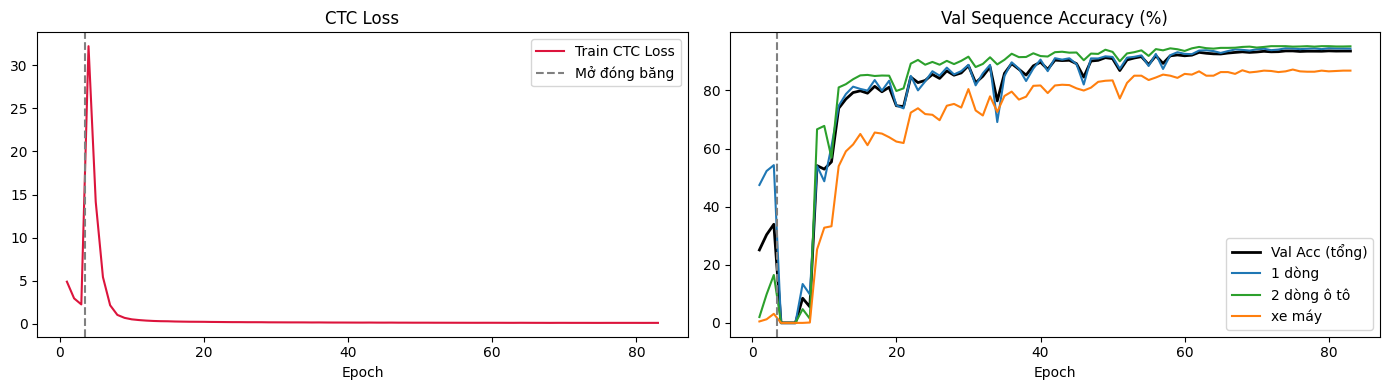

-> Đã lưu biểu đồ và lịch sử huấn luyện vào /content/drive/MyDrive/TGMT/lprnet_v5


In [19]:
criterion = nn.CTCLoss(blank=BLANK_IDX, zero_infinity=False)   # không che lỗi độ dài nhãn
TOTAL_EPOCHS = FROZEN_EPOCHS + FINETUNE_EPOCHS
steps_per_epoch = len(train_loader)

def phase_of(epoch):
    return "frozen" if epoch <= FROZEN_EPOCHS else "finetune"

def setup_phase(phase):
    for n, p in model.named_parameters():
        p.requires_grad = phase == "finetune" or n.startswith(HEAD_PREFIXES)
    if phase == "frozen":
        return optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR_HEAD), None
    opt = optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.OneCycleLR(opt, max_lr=MAX_LR, total_steps=FINETUNE_EPOCHS * steps_per_epoch, pct_start=0.1)
    return opt, sch

def set_train_mode(phase):
    model.train()
    if phase == "frozen":   # giữ nguyên thống kê BN của các tầng bị đóng băng
        for name, m in model.backbone.named_children():
            if isinstance(m, nn.BatchNorm2d) and not f"backbone.{name}.".startswith(HEAD_PREFIXES):
                m.eval()

def save_to_drive(obj, path):
    local = os.path.join(LOCAL_DIR, os.path.basename(path))
    torch.save(obj, local)
    shutil.copy(local, path)

start_epoch, best_acc, best_cer, history, ckpt = 1, -1.0, 1e9, [], None
if WEIGHTS_MODE == "resume":
    ckpt = torch.load(LAST_PATH, map_location=device, weights_only=False)
    assert ckpt.get("fingerprint") == DATA_FINGERPRINT, (
        "Dữ liệu/split/tiền xử lý đã khác lần train trước (vd. vừa sửa layout_corrections.csv). "
        "Không train tiếp lên checkpoint cũ: đổi SAVE_DIR hoặc đặt WEIGHTS_MODE = 'author'.")
    model.load_state_dict(ckpt["model"])
    start_epoch = ckpt["epoch"] + 1
    best_acc, best_cer, history = ckpt["best_acc"], ckpt["best_cer"], ckpt["history"]
    print(f"-> Train tiếp từ epoch {start_epoch} (best Val Acc hiện tại {best_acc:.2f}%)")

phase = phase_of(start_epoch)
optimizer, scheduler = setup_phase(phase)
if ckpt is not None and ckpt["phase"] == phase:
    optimizer.load_state_dict(ckpt["optimizer"])
    if scheduler is not None and ckpt["scheduler"] is not None:
        scheduler.load_state_dict(ckpt["scheduler"])

try:
    print()
    print(f"--- BẮT ĐẦU HUẤN LUYỆN: {FROZEN_EPOCHS} epoch Frozen + {FINETUNE_EPOCHS} epoch Fine-tune ---")
    for epoch in range(start_epoch, TOTAL_EPOCHS + 1):
        if phase_of(epoch) != phase:
            phase = phase_of(epoch)
            optimizer, scheduler = setup_phase(phase)
            print()
            print("-> CHUYỂN PHA 2: Mở đóng băng toàn bộ mạng, AdamW + OneCycleLR")

        set_train_mode(phase)
        t0, running_loss = time.time(), 0.0
        for imgs, targets, target_lengths, labels, _ in train_loader:
            imgs, targets = imgs.to(device, non_blocking=True), targets.to(device)
            logits = model(imgs)
            T, B, _ = logits.size()
            assert max(ctc_len(l) for l in labels) <= T, f"Nhãn quá dài cho {T} bước CTC: {labels}"
            input_lengths = torch.full((B,), T, dtype=torch.long)
            loss = criterion(logits.log_softmax(2), targets, input_lengths, target_lengths)
            if not torch.isfinite(loss):
                raise RuntimeError(f"CTC loss = {loss.item()} — kiểm tra nhãn/ảnh của batch: {labels[:8]}")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            running_loss += loss.item()

        res = summarize(predict(model, val_loader), val_samples)
        epoch_loss = running_loss / max(1, steps_per_epoch)
        lr_now = optimizer.param_groups[0]["lr"]
        history.append({"epoch": epoch, "phase": phase, "loss": epoch_loss, "lr": lr_now,
                        "val_acc": res["TỔNG"]["acc"], "val_cer": res["TỔNG"]["cer"],
                        **{f"acc_{g}": res[g]["acc"] for g in GROUPS if g in res}})
        group_str = " | ".join(f"{g}: {res[g]['acc']:.1f}%" for g in GROUPS if g in res)
        print(f"Epoch [{epoch:03d}/{TOTAL_EPOCHS}] {phase:8s} | lr {lr_now:.2e} | Loss {epoch_loss:.4f} | "
              f"Val Acc {res['TỔNG']['acc']:.2f}% | CER {res['TỔNG']['cer']:.4f} | {group_str} | {time.time() - t0:.0f}s")

        acc_now, cer_now = res["TỔNG"]["acc"], res["TỔNG"]["cer"]
        if acc_now > best_acc or (acc_now == best_acc and cer_now < best_cer):
            best_acc, best_cer = acc_now, cer_now
            save_to_drive(model.state_dict(), BEST_PATH)
            print(f"   [LƯU CHECKPOINT TỐT NHẤT] {BEST_PATH}")
        save_to_drive({"epoch": epoch, "phase": phase, "model": model.state_dict(),
                       "optimizer": optimizer.state_dict(),
                       "scheduler": scheduler.state_dict() if scheduler is not None else None,
                       "best_acc": best_acc, "best_cer": best_cer, "history": history,
                       "fingerprint": DATA_FINGERPRINT}, LAST_PATH)

    print()
    print(f"-> Huấn luyện hoàn tất! Checkpoint tốt nhất: {BEST_PATH} (Val Acc {best_acc:.2f}%, CER {best_cer:.4f})")
    frozen_hist = [h for h in history if h["phase"] == "frozen"]
    if frozen_hist:
        print(f"-> TN-OCR 1: Frozen (hết pha 1) = {frozen_hist[-1]['val_acc']:.2f}% | Fine-tuned (tốt nhất) = {best_acc:.2f}%")

    with open(f"{SAVE_DIR}/train_history.json", "w", encoding="utf-8") as f:
        json.dump(history, f, ensure_ascii=False, indent=1)
    ep = [h["epoch"] for h in history]
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, [h["loss"] for h in history], color="crimson", label="Train CTC Loss")
    plt.axvline(FROZEN_EPOCHS + 0.5, color="gray", ls="--", label="Mở đóng băng")
    plt.title("CTC Loss"); plt.xlabel("Epoch"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, [h["val_acc"] for h in history], color="black", lw=2, label="Val Acc (tổng)")
    for g, c in zip(GROUPS, ["tab:blue", "tab:green", "tab:orange"]):
        plt.plot(ep, [h.get(f"acc_{g}", np.nan) for h in history], color=c, label=g)
    plt.axvline(FROZEN_EPOCHS + 0.5, color="gray", ls="--")
    plt.title("Val Sequence Accuracy (%)"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/lprnet_v5_training_curves.png", dpi=300)
    plt.show()
    print(f"-> Đã lưu biểu đồ và lịch sử huấn luyện vào {SAVE_DIR}")

except KeyboardInterrupt:
    print()
    print(f"-> Đã dừng tay. Checkpoint cuối nằm ở {LAST_PATH}, đặt WEIGHTS_MODE = 'resume' để train tiếp.")
except Exception:
    print()
    print("PHÁT HIỆN LỖI TRONG QUÁ TRÌNH HUẤN LUYỆN:")
    traceback.print_exc()
    crash_path = f"{SAVE_DIR}/emergency_lprnet_vn_v5.pth"
    torch.save(model.state_dict(), crash_path)
    print(f"-> Đã lưu checkpoint khẩn cấp: {crash_path}")
    idle_shutdown_timer()

### 13. Đánh Giá Chính Thức Trên Tập Test Độc Lập (Số Liệu Cho Báo Cáo)
- Số liệu chính tính trên **toàn bộ Test**, kể cả mẫu đầu vào lỗi (bị tính là sai).
- Bảng theo cờ chất lượng chỉ để **giải thích** lỗi nằm ở đâu, không dùng để chọn mô hình.

In [20]:
best_model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
best_model.load_state_dict(torch.load(BEST_PATH, map_location=device))
print(f"-> Đã nạp checkpoint tốt nhất: {BEST_PATH}")

test_records = predict(best_model, test_loader)
predict.n_fallback = 0
t0 = time.time()
test_records_c = predict(best_model, test_loader, constrained=True)
cons_ms = (time.time() - t0) / max(1, len(test_records_c)) * 1000
res_raw = summarize(test_records, test_samples)
res_fix = summarize(test_records, test_samples, fix=True)
res_con = summarize(test_records_c, test_samples)
print_summary(res_raw, "KẾT QUẢ TEST – LPRNet (giải mã greedy, chưa hậu xử lý)")
print_summary(res_fix, "KẾT QUẢ TEST – LPRNet + hậu xử lý định dạng biển VN (greedy + fix_vn_plate)")
print_summary(res_con, "KẾT QUẢ TEST – LPRNet + giải mã ràng buộc định dạng (beam search) ← KẾT QUẢ CHÍNH")
greedy_pred = {i: p for i, _, p in test_records}
n_gain = sum(p == gt and greedy_pred[i] != gt for i, gt, p in test_records_c)
n_loss = sum(p != gt and greedy_pred[i] == gt for i, gt, p in test_records_c)
print(f"-> So với greedy: sửa đúng {n_gain} ảnh, làm sai {n_loss} ảnh vốn đúng | "
      f"{predict.n_fallback} ảnh không có chuỗi hợp lệ (dùng greedy) | {cons_ms:.2f} ms/ảnh (gồm cả mô hình)")

def flag_table(records, samples, title="KẾT QUẢ TEST THEO CỜ CHẤT LƯỢNG (giải mã ràng buộc định dạng)"):
    print("=" * 84)
    print(title)
    print("-" * 84)
    print(f"{'Cờ':26s}{'n':>7s}{'Seq Acc':>11s}{'CER':>9s}   " + " | ".join(GROUPS))
    rows = [("ảnh sạch (không cờ)", lambda s: not s.get("flags"))] + [(f, lambda s, f=f: f in s.get("flags", [])) for f in FLAG_NAMES]
    out = {}
    for name, cond in rows:
        sub = [(i, gt, p) for i, gt, p in records if cond(samples[i])]
        if not sub:
            continue
        r = summarize(sub, samples)
        out[name] = r
        per_g = " | ".join(f"{r[g]['acc']:.1f}% (n={r[g]['n']})" if g in r else "-" for g in GROUPS)
        print(f"{name:26s}{r['TỔNG']['n']:7d}{r['TỔNG']['acc']:10.2f}%{r['TỔNG']['cer']:9.4f}   {per_g}")
    print("=" * 84)
    return out

res_flags = flag_table(test_records_c, test_samples)

import csv
with open(f"{SAVE_DIR}/test_predictions.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["img_path", "group", "two_rows", "gt", "pred_greedy", "pred_fixed", "pred_constrained",
                "correct_greedy", "correct_fixed", "correct_constrained", "flags"])
    for (i, gt, p), (_, _, pc) in zip(test_records, test_records_c):
        s = test_samples[i]
        w.writerow([s["img_path"], s["group"], int(s["is_two_rows"]), gt, p, fix_vn_plate(p), pc, int(p == gt),
                    int(fix_vn_plate(p) == gt), int(pc == gt), ";".join(s.get("flags", []))])
with open(f"{SAVE_DIR}/test_results.json", "w", encoding="utf-8") as f:
    json.dump({"raw": res_raw, "fixed": res_fix, "constrained": res_con, "by_flag": res_flags, "fingerprint": DATA_FINGERPRINT,
               "split_method": SPLIT_METHOD}, f, ensure_ascii=False, indent=1)
print(f"-> Đã lưu toàn bộ dự đoán Test: {SAVE_DIR}/test_predictions.csv")
print("👉 Điền Sequence Accuracy và CER (tổng và từng nhóm) vào bảng thực nghiệm Chương 3!")

-> Đã nạp checkpoint tốt nhất: /content/drive/MyDrive/TGMT/lprnet_v5/best_lprnet_vn_v5.pth
KẾT QUẢ TEST – LPRNet (giải mã greedy, chưa hậu xử lý)
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2905        93.67%      0.0111
2 dòng ô tô       1918        95.57%      0.0086
xe máy             826        88.01%      0.0220
TỔNG              5649        93.49%      0.0120
KẾT QUẢ TEST – LPRNet + hậu xử lý định dạng biển VN (greedy + fix_vn_plate)
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2905        93.67%      0.0114
2 dòng ô tô       1918        95.57%      0.0089
xe máy             826        88.01%      0.0229
TỔNG              5649        93.49%      0.0124
KẾT QUẢ TEST – LPRNet + giải mã ràng buộc định dạng (beam search) ← KẾT QUẢ CHÍNH
--------------------------------------------------------
Nhóm                 n       Seq Ac

### 14. Phân Tích & In Ảnh Các Dự Đoán Lỗi Trên Tập Test
Phân tích trên **kết quả chính** (giải mã ràng buộc định dạng). Mỗi hàng gồm ảnh gốc (khung bbox) và ảnh đầu vào mô hình, kèm `GT → dự đoán` và kết quả greedy nếu khác. Bảng **độ chính xác theo từng chữ cái** cho biết chữ nào thật sự yếu (K, X, G, R...) và hay bị nhầm thành chữ gì. Hình được lưu vào Drive để đưa vào báo cáo.

In [21]:
import difflib

errors = [(i, gt, p) for i, gt, p in test_records_c if p != gt]
print(f"-> Tổng số mẫu sai trên Test: {len(errors)} / {len(test_records)}")

def error_kind(gt, p):
    d = len(p) - len(gt)
    if d <= -3:
        return "hỏng nặng (thiếu ≥3)"
    if d == 0:
        return "thay thế"
    return "thiếu 1-2" if d < 0 else "thừa"

kinds = Counter((test_samples[i]["group"], error_kind(gt, p)) for i, gt, p in errors)
kind_names = ["thay thế", "thiếu 1-2", "thừa", "hỏng nặng (thiếu ≥3)"]
print()
print(f"{'Nhóm':14s}" + "".join(f"{k:>22s}" for k in kind_names))
for g in GROUPS:
    print(f"{g:14s}" + "".join(f"{kinds[(g, k)]:22d}" for k in kind_names))

confusions = Counter()
for _, gt, p in errors:
    for op, a0, a1, b0, b1 in difflib.SequenceMatcher(None, gt, p, autojunk=False).get_opcodes():
        if op == "replace" and a1 - a0 == b1 - b0:
            confusions.update(f"{x}→{y}" for x, y in zip(gt[a0:a1], p[b0:b1]))
        elif op in ("delete", "replace"):
            confusions.update(f"{x}→∅" for x in gt[a0:a1])
        if op == "insert" or (op == "replace" and a1 - a0 != b1 - b0):
            confusions.update(f"∅→{y}" for y in p[b0:b1])
print()
print("20 cặp nhầm lẫn ký tự phổ biến nhất (∅ = thiếu / thừa ký tự):")
print("   " + " | ".join(f"{k}: {v}" for k, v in confusions.most_common(20)))

# Độ chính xác theo từng chữ cái: một chữ trong nhãn được tính đúng nếu nằm trong đoạn khớp giữa nhãn và dự đoán
def letter_report(records, samples):
    hit, tot, wrong_as = Counter(), Counter(), defaultdict(Counter)
    for i, gt, p in records:
        if not samples[i]["input_ok"]:
            continue
        for op, a0, a1, b0, b1 in difflib.SequenceMatcher(None, gt, p, autojunk=False).get_opcodes():
            for k in range(a0, a1):
                c = gt[k]
                if not c.isalpha():
                    continue
                tot[c] += 1
                if op == "equal":
                    hit[c] += 1
                elif op == "replace" and a1 - a0 == b1 - b0:
                    wrong_as[c][p[b0 + k - a0]] += 1
                else:
                    wrong_as[c]["∅"] += 1
    print("=" * 84)
    print("ĐỘ CHÍNH XÁC THEO TỪNG CHỮ CÁI TRÊN TEST (xếp theo độ chính xác tăng dần)")
    print("-" * 84)
    print(f"{'Chữ':5s}{'train':>8s}{'test':>7s}{'đúng':>9s}   hay bị nhầm thành")
    for c in sorted(tot, key=lambda c: hit[c] / tot[c]):
        conf = ", ".join(f"{y} ({n})" for y, n in wrong_as[c].most_common(3))
        print(f"{c:5s}{train_letter_cnt[c]:8d}{tot[c]:7d}{100 * hit[c] / tot[c]:8.1f}%   {conf}")
    print("=" * 84)

letter_report(test_records_c, test_samples)

GROUP_SLUG = {"1 dòng": "1_dong", "2 dòng ô tô": "2_dong_oto", "xe máy": "xe_may"}

def show_errors(errs, title, n=16, seed=0, save_name=None):
    if not errs:
        print(f"(Không có lỗi: {title})")
        return
    picks = random.Random(seed).sample(errs, min(n, len(errs)))
    fig, axes = plt.subplots(len(picks), 2, figsize=(12, 2.0 * len(picks)), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.5]})
    for r, (i, gt, p) in enumerate(picks):
        s = test_samples[i]
        img = read_image(s["img_path"])
        axes[r, 0].imshow(full_with_boxes(s, img))
        flag_str = (" | " + ", ".join(s.get("flags", []))) if s.get("flags") else ""
        axes[r, 0].set_title(os.path.basename(s["img_path"])[:45] + flag_str, fontsize=7)
        axes[r, 1].imshow(bgr2rgb(model_input(img, s, is_train=False)))
        pg = greedy_pred[i]
        note = f"  | greedy: {pg}" if pg != p else ""
        axes[r, 1].set_title(f"GT {gt}  →  {p}{note}", fontsize=10, color="crimson")
        for a in axes[r]:
            a.axis("off")
    add_title(fig, title)
    if save_name:
        fig.savefig(f"{SAVE_DIR}/{save_name}", dpi=120)
    plt.show()

for g in GROUPS:
    g_err = [e for e in errors if test_samples[e[0]]["group"] == g]
    show_errors(g_err, f"LỖI DỰ ĐOÁN TRÊN TEST – {g} ({len(g_err)} mẫu sai)", save_name=f"test_errors_{GROUP_SLUG[g]}.png")
print(f"-> Đã lưu hình lỗi vào {SAVE_DIR}/test_errors_*.png")

Output hidden; open in https://colab.research.google.com to view.

### 15. Hàm Suy Luận Cho Pipeline YOLO → LPRNet
Khi chạy thực tế, không có nhãn 1 dòng/2 dòng. Hàm dưới đây đoán từ tỉ lệ rộng/cao của bbox YOLO (ngưỡng tìm ở Bước 4). Ô này cũng đo xem việc đoán đó làm giảm độ chính xác bao nhiêu so với dùng nhãn thật.

In [22]:
@torch.no_grad()
def recognize_plate(net, img_bgr, bbox, is_two_rows=None):
    """img_bgr: khung hình gốc (BGR), bbox: (xmin, ymin, xmax, ymax) từ YOLO."""
    xmin, ymin, xmax, ymax = map(int, bbox)
    if is_two_rows is None:
        is_two_rows = (xmax - xmin) / max(1, ymax - ymin) < TWO_ROW_RATIO_THR
    s = {"bbox": (xmin, ymin, xmax, ymax), "mode": "full", "is_two_rows": is_two_rows}
    x = to_tensor(preprocess(img_bgr, s, is_train=False))[None].to(device)
    net.eval()
    logits = net(x)
    c = decode_constrained(logits.log_softmax(2)[:, 0].cpu().numpy(), is_two_rows)
    return c if c is not None else fix_vn_plate(decode_greedy(logits)[0])

check = [s for s in random.Random(0).sample(test_samples, min(1000, len(test_samples))) if s["mode"] == "full" and s["input_ok"]]
hits_label = hits_guess = 0
for s in check:
    img = read_image(s["img_path"])
    hits_label += recognize_plate(best_model, img, s["bbox"], s["is_two_rows"]) == s["label"]
    hits_guess += recognize_plate(best_model, img, s["bbox"]) == s["label"]
print(f"-> {len(check)} ảnh Test: dùng nhãn 1/2 dòng thật = {100 * hits_label / max(1, len(check)):.2f}% | "
      f"đoán từ tỉ lệ bbox = {100 * hits_guess / max(1, len(check)):.2f}%")

-> 1000 ảnh Test: dùng nhãn 1/2 dòng thật = 93.70% | đoán từ tỉ lệ bbox = 90.70%


### 15.1 Nối MobileNetV3-Small (phân loại 1/2 dòng) → LPRNet
LPRNet là mô hình OCR chính của pipeline, CRNN chỉ dùng để đối chiếu. Luồng xử lý:

`khung hình + bbox YOLO` → crop 3% → letterbox 128×128 → **MobileNetV3-Small** (`one_row` / `two_rows`) → crop của LPRNet (đệm 3% / 6%) → biển 1 dòng: 94×24 | biển 2 dòng: tách khe nghiêng → 188×24 → **LPRNet** → giải mã CTC.

- MobileNet chỉ thay **nhãn 1/2 dòng**. LPRNet vẫn tự crop và tự tách 2 dòng theo đúng hàm `preprocess` lúc train, **không** dùng ảnh tách–ghép 256×32 của CRNN.
- Ô 15.1 cần checkpoint `layout_best.pt` của notebook MobileNet: sửa `LAYOUT_CKPT`. Các tham số `LAYOUT_*` phải giống notebook MobileNet. Ô 15.2 tự kiểm tra accuracy bố cục trên Val: nếu thấp hơn nhiều so với 99,9% trong báo cáo thì tiền xử lý đang lệch.
- **Rò rỉ dữ liệu:** LPRNet chia 70/15/15 riêng, MobileNet dùng `split_manifest.csv` (80/10/10), nên phần lớn ảnh Test ở đây MobileNet đã thấy lúc train. Nếu đặt `split_manifest.csv` vào `SPLIT_MANIFEST`, bảng kết quả có thêm dòng *chỉ ảnh Test của MobileNet* (sạch với cả hai mô hình). Số liệu chốt cho báo cáo nên lấy sau khi train LPRNet theo cùng manifest.
- Chỉ muốn chạy phần này (không train lại): chạy Bước 1 → 10, rồi 15.1 → 15.5. Ô 15.1 tự nạp `best_lprnet_vn_v5.pth` nếu chưa có `best_model`.
- Kết quả lưu ở `pipeline_test_predictions.csv`, `pipeline_test_results.json`, và `plate_grammar.json` (cho `lprnet_v5_infer.py`).

In [ ]:
# ==============================================================================
# BƯỚC 15.1: NẠP MobileNetV3-Small PHÂN LOẠI BỐ CỤC (one_row / two_rows)
# ==============================================================================
import torchvision

# --- Phải khớp notebook MobileNet (báo cáo Mục 2.2.3 và 3.5) ---
LAYOUT_CKPT      = f"{DRIVE_DIR}/mobilenet_layout/layout_best.pt"   # ĐỔI theo nơi lưu checkpoint MobileNet trên Drive
LAYOUT_CLASSES   = ["one_row", "two_rows"]   # thứ tự lớp lúc train; bị ghi đè nếu checkpoint có lưu tên lớp
LAYOUT_SIZE      = 128                        # letterbox về 128x128
LAYOUT_PAD_RATIO = 0.03                       # biên crop quanh bbox (notebook CRNN/MobileNet dùng 3%)
LAYOUT_PAD_VALUE = 114                        # màu nền xám khi letterbox
LAYOUT_TWO_THR   = 0.5                        # P(two_rows) >= ngưỡng -> biển 2 dòng
IMAGENET_MEAN    = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD     = np.array([0.229, 0.224, 0.225], np.float32)
SPLIT_MANIFEST   = f"{DRIVE_DIR}/split_manifest.csv"   # split chung của CRNN/MobileNet (không bắt buộc), dùng để lọc ảnh rò rỉ

if "best_model" not in globals():   # chạy thẳng Bước 1–10 rồi tới đây, bỏ qua Bước 11–14
    best_model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
    best_model.load_state_dict(torch.load(BEST_PATH, map_location=device))
    print(f"-> Đã nạp LPRNet: {BEST_PATH}")
best_model.eval()

# Ngữ pháp biển số cho giải mã ràng buộc. lprnet_v5_infer.py đọc file này; thiếu file thì script
# dùng ngữ pháp tổng quát và kết quả sẽ khác notebook.
GRAMMAR_PATH = f"{SAVE_DIR}/plate_grammar.json"
with open(GRAMMAR_PATH, "w", encoding="utf-8") as f:
    json.dump({"provinces": sorted(PROVINCES), "series": sorted(SERIES),
               "digit_lens": {"one_row": sorted(DIGIT_LENS[False]), "two_rows": sorted(DIGIT_LENS[True])}},
              f, ensure_ascii=False, indent=1)
print(f"-> Đã xuất ngữ pháp biển số: {GRAMMAR_PATH}")

def load_layout_model(path):
    """Nhận state_dict thuần, dict có model_state_dict / state_dict / model, hoặc cả mô hình đã torch.save."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không thấy checkpoint MobileNet: {path}. Sửa LAYOUT_CKPT ở đầu ô này.")
    ck = torch.load(path, map_location="cpu", weights_only=False)
    classes = None
    if isinstance(ck, nn.Module):
        net = ck
    else:
        sd = ck
        if isinstance(ck, dict):
            for key in ("model_state_dict", "state_dict", "model"):
                if isinstance(ck.get(key), dict):
                    sd = ck[key]
                    break
            if isinstance(ck.get("classes"), (list, tuple)):
                classes = list(ck["classes"])
            elif isinstance(ck.get("class_names"), (list, tuple)):
                classes = list(ck["class_names"])
            elif isinstance(ck.get("class_to_idx"), dict):
                classes = sorted(ck["class_to_idx"], key=ck["class_to_idx"].get)
            elif isinstance(ck.get("idx_to_class"), dict):
                classes = [ck["idx_to_class"][k] for k in sorted(ck["idx_to_class"], key=int)]
        sd = {k.replace("module.", ""): v for k, v in sd.items()}
        net = torchvision.models.mobilenet_v3_small(weights=None)
        net.classifier[3] = nn.Linear(net.classifier[3].in_features, 2)
        try:
            net.load_state_dict(sd, strict=True)
        except RuntimeError as e:
            print("Tên tensor trong checkpoint (10 cái đầu):", list(sd)[:10])
            raise RuntimeError("Checkpoint không khớp mobilenet_v3_small + Linear 2 lớp. "
                               "Hãy chép đúng đoạn tạo mô hình từ notebook MobileNet vào đây.") from e
    return net.to(device).eval(), classes or list(LAYOUT_CLASSES)

layout_net, layout_classes = load_layout_model(LAYOUT_CKPT)
two_ids = [i for i, c in enumerate(layout_classes) if "two" in str(c).lower() or str(c).startswith("2")]
assert len(two_ids) == 1, f"Không xác định được lớp two_rows trong {layout_classes}"
TWO_IDX = two_ids[0]
print(f"-> Đã nạp MobileNetV3-Small: {LAYOUT_CKPT}")
print(f"   Lớp: {layout_classes} (two_rows = chỉ số {TWO_IDX}) | "
      f"{sum(p.numel() for p in layout_net.parameters()) / 1e6:.2f}M tham số")

#### 15.2 Tiền xử lý cho MobileNet và kiểm tra accuracy bố cục trên Val

In [ ]:
# ==============================================================================
# BƯỚC 15.2: TIỀN XỬ LÝ CHO MobileNet + KIỂM TRA TRÊN VAL
# ==============================================================================
def layout_crop(img, bbox, pad=LAYOUT_PAD_RATIO):
    """Crop cho MobileNet (biên 3%), KHÁC crop cho LPRNet (đệm 3% ngang / 6% dọc trong get_plate_crop)."""
    h, w = img.shape[:2]
    xmin, ymin, xmax, ymax = bbox
    bw, bh = xmax - xmin, ymax - ymin
    x0, y0 = max(0, int(round(xmin - pad * bw))), max(0, int(round(ymin - pad * bh)))
    x1, y1 = min(w, int(round(xmax + pad * bw))), min(h, int(round(ymax + pad * bh)))
    c = img[y0:y1, x0:x1]
    return c if c.size else img

def layout_input(crop_bgr):
    """Letterbox giữ tỉ lệ về 128x128 trên nền xám, BGR -> RGB, chuẩn hoá mean/std ImageNet."""
    h, w = crop_bgr.shape[:2]
    r = LAYOUT_SIZE / max(h, w)
    nw, nh = max(1, round(w * r)), max(1, round(h * r))
    canvas = np.full((LAYOUT_SIZE, LAYOUT_SIZE, 3), LAYOUT_PAD_VALUE, np.uint8)
    x0, y0 = (LAYOUT_SIZE - nw) // 2, (LAYOUT_SIZE - nh) // 2
    canvas[y0:y0 + nh, x0:x0 + nw] = cv2.resize(crop_bgr, (nw, nh), interpolation=cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR)
    x = (cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class LayoutDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        img = read_image(s["img_path"]) if s["input_ok"] else None
        if img is None:   # đầu vào lỗi: vẫn cho một dự đoán, OCR của mẫu này bị đặt rỗng ở predict()
            return torch.zeros(3, LAYOUT_SIZE, LAYOUT_SIZE), i
        crop = img if s["mode"] == "crop" else layout_crop(img, s["bbox"])
        return layout_input(crop), i

@torch.no_grad()
def predict_layout(samples, bs=256):
    """P(two_rows) cho từng mẫu."""
    loader = DataLoader(LayoutDataset(samples), batch_size=bs, shuffle=False, num_workers=NUM_WORKERS)
    prob = np.zeros(len(samples), np.float32)
    for x, idx in loader:
        prob[idx.numpy()] = layout_net(x.to(device)).softmax(1)[:, TWO_IDX].float().cpu().numpy()
    return prob

def layout_report(samples, prob, name):
    gt = np.array([s["is_two_rows"] for s in samples])
    pred = prob >= LAYOUT_TWO_THR
    acc = (gt == pred).mean()
    print(f"-> {name}: accuracy bố cục = {100 * acc:.3f}% ({int((gt == pred).sum())}/{len(gt)}) | "
          f"1 dòng → 2 dòng: {int((~gt & pred).sum())} | 2 dòng → 1 dòng: {int((gt & ~pred).sum())}")
    return acc

# Split chung của CRNN/MobileNet: ảnh Test của LPRNet mà MobileNet đã thấy lúc train thì accuracy bố cục bị lạc quan
def load_manifest_splits(path):
    if not os.path.exists(path):
        print(f"-> Không có {path}: bỏ qua bước lọc ảnh rò rỉ giữa hai cách chia tập.")
        return None
    with open(path, encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    cols = list(rows[0]) if rows else []
    split_col = next((c for c in cols if c.strip().lower() in ("split", "subset", "set", "phase", "partition")), None)
    path_col = next((c for c in cols if any(k in c.lower() for k in ("file", "path", "image", "img", "name"))), None)
    if not (split_col and path_col):
        print(f"-> Không nhận ra cột tên ảnh / cột split trong {path} (các cột: {cols}), bỏ qua.")
        return None
    splits = {os.path.basename(r[path_col].strip()): r[split_col].strip().lower() for r in rows}
    print(f"-> Đọc split_manifest: {len(splits)} ảnh, cột '{path_col}' / '{split_col}': {dict(Counter(splits.values()))}")
    return splits

manifest_split = load_manifest_splits(SPLIT_MANIFEST)

def mb_split(s):
    if manifest_split is None:
        return ""
    return manifest_split.get(os.path.basename(s["img_path"]), "không có")

val_prob = predict_layout(val_samples)
val_acc = layout_report(val_samples, val_prob, "Val LPRNet")
if val_acc < 0.5:
    raise RuntimeError("Accuracy < 50%: thứ tự lớp gần như chắc chắn bị ngược. Đổi LAYOUT_CLASSES = ['two_rows', 'one_row'].")
if val_acc < 0.98:
    print("   [CẢNH BÁO] Thấp hơn nhiều so với 99,9% trong báo cáo: kiểm tra LAYOUT_PAD_RATIO, LAYOUT_PAD_VALUE, "
          "letterbox căn giữa hay góc trên, và thứ tự lớp so với notebook MobileNet.")
if manifest_split is not None:
    print("   Ảnh Val của LPRNet theo split của MobileNet:", dict(Counter(mb_split(s) for s in val_samples)))

#### 15.3 Đánh giá LPRNet theo 3 nguồn bố cục trên cùng tập Test
Cùng ảnh, cùng checkpoint LPRNet, chỉ đổi nguồn nhãn 1/2 dòng: (A) nhãn chuẩn VNLP, (B) MobileNet dự đoán, (C) tỉ lệ rộng/cao bbox (`TWO_ROW_RATIO_THR`). Bảng gom theo **bố cục thật** để các nhánh so trên cùng mẫu. Cột *greedy* dùng để đối chiếu với CRNN; cột *ràng buộc* là kết quả chính của LPRNet. Đây vẫn là phép thử trên crop nhãn chuẩn, **chưa phải end-to-end** vì chưa có YOLO.

In [ ]:
# ==============================================================================
# BƯỚC 15.3: ĐÁNH GIÁ MobileNet → LPRNet TRÊN TEST (so với nhãn bố cục chuẩn và tỉ lệ bbox)
# ==============================================================================
test_prob = predict_layout(test_samples)
layout_report(test_samples, test_prob, "Test LPRNet")

def with_layout(samples, two):
    # bản sao mẫu với nhãn 1/2 dòng thay thế; ảnh, bbox, nhãn chuỗi giữ nguyên
    return [{**s, "is_two_rows": bool(t)} for s, t in zip(samples, two)]

def run_branch(samples):
    ld = make_loader(samples, is_train=False)
    greedy = predict(best_model, ld)
    predict.n_fallback = 0
    return greedy, predict(best_model, ld, constrained=True)

BRANCHES = {
    "Bố cục chuẩn (nhãn VNLP)": test_samples,
    "Bố cục MobileNet":         with_layout(test_samples, test_prob >= LAYOUT_TWO_THR),
    "Bố cục theo tỉ lệ bbox":   with_layout(test_samples, [plate_ratio(s) < TWO_ROW_RATIO_THR for s in test_samples]),
}
branch_out = {name: run_branch(ss) for name, ss in BRANCHES.items()}

def seq_cer(recs):
    n = len(recs)
    ok = sum(p == gt for _, gt, p in recs)
    ed = sum(editdistance.eval(p, gt) for _, gt, p in recs)
    ch = sum(len(gt) for _, gt, _ in recs)
    return n, ok, ok / max(1, n), ed / max(1, ch)

# Gom theo nhãn bố cục THẬT (không theo bố cục dự đoán) để các nhánh so trên cùng tập mẫu, khớp Bảng 3.3 / 4.3
SUBSETS = {"TỔNG": lambda s: True, "1 dòng": lambda s: not s["is_two_rows"], "2 dòng": lambda s: s["is_two_rows"]}
if manifest_split is not None:
    SUBSETS["TỔNG, chỉ ảnh Test của MobileNet"] = lambda s: mb_split(s) == "test"

def branch_table():
    print("=" * 104)
    print("LPRNet TRÊN TEST THEO NGUỒN BỐ CỤC  (Seq Acc % | CER)")
    print("-" * 104)
    print(f"{'Nguồn bố cục':28s}{'Tập con':36s}{'n':>6s}{'greedy':>17s}{'ràng buộc':>17s}")
    out = {}
    for name, (g, c) in branch_out.items():
        for sub, cond in SUBSETS.items():
            rg = [r for r in g if cond(test_samples[r[0]])]
            rc = [r for r in c if cond(test_samples[r[0]])]
            if not rg:
                continue
            n, _, ag, cg = seq_cer(rg)
            _, _, ac, cc = seq_cer(rc)
            out[f"{name} | {sub}"] = {"n": n, "acc_greedy": ag, "cer_greedy": cg, "acc_constrained": ac, "cer_constrained": cc}
            print(f"{name:28s}{sub:36s}{n:6d}{100 * ag:9.2f}% {cg:.4f}{100 * ac:9.2f}% {cc:.4f}")
    print("=" * 104)
    return out

res_branches = branch_table()
print("greedy: để đối chiếu với CRNN (cũng greedy). ràng buộc: kết quả chính của LPRNet, báo cáo riêng như mô-đun hiệu chỉnh.")

def paired(a, b):
    # so ghép cặp từng mẫu giữa 2 nhánh (giống phân tích Mục 4.5)
    pa, pb = {i: p == gt for i, gt, p in a}, {i: p == gt for i, gt, p in b}
    return Counter((pa[i], pb[i]) for i in pa)

ref, mb = branch_out["Bố cục chuẩn (nhãn VNLP)"], branch_out["Bố cục MobileNet"]
for k, dec in ((0, "greedy"), (1, "ràng buộc")):
    c = paired(ref[k], mb[k])
    print(f"-> Ghép cặp ({dec}): cùng đúng {c[(True, True)]} | cùng sai {c[(False, False)]} | "
          f"chỉ MobileNet đúng {c[(False, True)]} | chỉ bố cục chuẩn đúng {c[(True, False)]}")

# Các ảnh MobileNet đoán sai bố cục và OCR ở từng nhánh
pred_c = {name: {i: p for i, _, p in c} for name, (_, c) in branch_out.items()}
wrong_layout = [i for i, s in enumerate(test_samples) if (test_prob[i] >= LAYOUT_TWO_THR) != s["is_two_rows"]]
print(f"\n-> {len(wrong_layout)} ảnh Test MobileNet đoán sai bố cục:")
for i in wrong_layout[:30]:
    s = test_samples[i]
    print(f"   {os.path.basename(s['img_path'])[:46]:46s} thật={'2 dòng' if s['is_two_rows'] else '1 dòng'} "
          f"P(2 dòng)={test_prob[i]:.3f} | GT {s['label']} | OCR bố cục chuẩn: {pred_c['Bố cục chuẩn (nhãn VNLP)'][i]} "
          f"| OCR MobileNet: {pred_c['Bố cục MobileNet'][i]}")

# Lưu dự đoán để truy vết (Mục 2.7.1) và số liệu cho Bảng 4.3
names = list(branch_out)
gre = {n: {i: p for i, _, p in branch_out[n][0]} for n in names}
with open(f"{SAVE_DIR}/pipeline_test_predictions.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["img_path", "group", "gt_two_rows", "mb_prob_two_rows", "mb_two_rows", "ratio_two_rows", "mb_split", "gt",
                "gt_layout_greedy", "gt_layout_constrained", "mb_greedy", "mb_constrained", "ratio_greedy", "ratio_constrained"])
    for i, s in enumerate(test_samples):
        w.writerow([s["img_path"], s["group"], int(s["is_two_rows"]), f"{test_prob[i]:.4f}", int(test_prob[i] >= LAYOUT_TWO_THR),
                    int(BRANCHES[names[2]][i]["is_two_rows"]), mb_split(s), s["label"]]
                   + [d[n][i] for n in names for d in (gre, pred_c)])
with open(f"{SAVE_DIR}/pipeline_test_results.json", "w", encoding="utf-8") as f:
    json.dump({"layout_ckpt": LAYOUT_CKPT, "layout_classes": layout_classes, "two_thr": LAYOUT_TWO_THR,
               "val_layout_acc": float(val_acc), "branches": res_branches, "fingerprint": DATA_FINGERPRINT},
              f, ensure_ascii=False, indent=1)
print(f"\n-> Đã lưu {SAVE_DIR}/pipeline_test_predictions.csv và pipeline_test_results.json")

#### 15.4 Hàm suy luận cho ảnh / video thật
`recognize_plate_pipeline(img_bgr, bbox)` nhận khung hình BGR và bbox YOLO, trả về bố cục, xác suất 2 dòng, cờ tách hàng, chuỗi greedy thô và chuỗi sau giải mã ràng buộc. Truyền đúng `results[0].orig_img` của YOLO, không đọc lại file và không đổi sang RGB.

In [ ]:
# ==============================================================================
# BƯỚC 15.4: HÀM SUY LUẬN YOLO bbox → MobileNet → LPRNet (dùng cho ảnh / video thật)
# ==============================================================================
@torch.no_grad()
def recognize_plate_pipeline(img_bgr, bbox, lpr_net=None, two_thr=LAYOUT_TWO_THR):
    """img_bgr: khung hình gốc BGR, đúng mảng YOLO đã xử lý (results[0].orig_img).
    bbox: (xmin, ymin, xmax, ymax) toạ độ ảnh gốc, lấy từ results[0].boxes.xyxy.
    Trả dict giữ đủ thông tin truy vết lỗi theo Mục 2.7.1 của báo cáo."""
    lpr_net = best_model if lpr_net is None else lpr_net
    box = tuple(int(round(float(v))) for v in bbox)
    p_two = float(layout_net(layout_input(layout_crop(img_bgr, box))[None].to(device)).softmax(1)[0, TWO_IDX])
    two = p_two >= two_thr
    s = {"bbox": box, "mode": "full", "is_two_rows": two}
    gap_ok = bool(row_cut(get_plate_crop(img_bgr, s))[1]) if two else True
    lpr_net.eval()
    logits = lpr_net(to_tensor(preprocess(img_bgr, s, is_train=False))[None].to(device))
    raw = decode_greedy(logits)[0]
    con = decode_constrained(logits.log_softmax(2)[:, 0].cpu().numpy(), two)
    return {
        "bbox": box,
        "layout": "two_rows" if two else "one_row",
        "layout_prob_two_rows": p_two,
        "split_ok": gap_ok,                 # False: khe giữa 2 dòng không rõ, nên xem lại ảnh
        "text_raw": raw,                    # greedy, chưa hiệu chỉnh (giữ để truy vết)
        "text_constrained": con,            # None nếu không có chuỗi hợp lệ theo ngữ pháp
        "text": con if con is not None else fix_vn_plate(raw),
    }

# Chạy thử trên vài ảnh Test, dùng bbox nhãn thay cho bbox YOLO
for s in random.Random(1).sample([s for s in test_samples if s["mode"] == "full" and s["input_ok"]], 6):
    out = recognize_plate_pipeline(read_image(s["img_path"]), s["bbox"])
    print(f"GT {s['label']:10s} ({'2 dòng' if s['is_two_rows'] else '1 dòng'}) -> {out}")

# Cách nối với YOLOv8n (bỏ comment khi có trọng số detector):
# from ultralytics import YOLO
# detector = YOLO(f"{DRIVE_DIR}/yolov8n_plate/best.pt")
# res = detector(frame_bgr, imgsz=640, conf=0.25, iou=0.6, verbose=False)[0]
# plates = [{**recognize_plate_pipeline(res.orig_img, b), "det_conf": float(c)}
#           for b, c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy())]

#### 15.5 Đo thời gian nhánh MobileNet → LPRNet

In [ ]:
# ==============================================================================
# BƯỚC 15.5: ĐO THỜI GIAN NHÁNH MobileNet → TIỀN XỬ LÝ → LPRNet (cùng cách đo Bảng 4.5)
# ==============================================================================
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def timed_pipeline(img, bbox):
    t0 = time.perf_counter()
    x = layout_input(layout_crop(img, bbox))[None].to(device)
    p_two = float(layout_net(x).softmax(1)[0, TWO_IDX])
    t1 = time.perf_counter()
    two = p_two >= LAYOUT_TWO_THR
    xin = to_tensor(preprocess(img, {"bbox": bbox, "mode": "full", "is_two_rows": two}, is_train=False))[None].to(device)
    sync()
    t2 = time.perf_counter()
    logits = best_model(xin)
    lp = logits.log_softmax(2)[:, 0].cpu().numpy()
    raw = decode_greedy(logits)[0]
    con = decode_constrained(lp, two)
    t3 = time.perf_counter()
    return two, (t1 - t0) * 1000, (t2 - t1) * 1000, (t3 - t2) * 1000

bench = random.Random(0).sample([s for s in test_samples if s["mode"] == "full" and s["input_ok"]], 200)
bench_imgs = [read_image(s["img_path"]) for s in bench]   # nạp sẵn vào RAM, không tính thời gian đọc file
for img, s in zip(bench_imgs[:20], bench[:20]):            # warm-up
    timed_pipeline(img, s["bbox"])
rows = [timed_pipeline(img, s["bbox"]) for _ in range(3) for img, s in zip(bench_imgs, bench)]

gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("=" * 78)
print(f"THỜI GIAN MỖI CROP: {len(rows)} lượt ({len(bench)} ảnh x 3), {gpu}, FP32, batch = 1")
print("-" * 78)
print(f"{'Công đoạn':40s}{'mean (ms)':>12s}{'median':>12s}{'p95':>12s}")
parts = [("MobileNet dự đoán bố cục", 1), ("Crop + tách–ghép + resize (LPRNet)", 2), ("LPRNet + giải mã greedy & ràng buộc", 3)]
for name, k in parts:
    v = np.array([r[k] for r in rows])
    print(f"{name:40s}{v.mean():12.3f}{np.median(v):12.3f}{np.percentile(v, 95):12.3f}")
tot = np.array([r[1] + r[2] + r[3] for r in rows])
print(f"{'Tổng nhánh đã đo':40s}{tot.mean():12.3f}{np.median(tot):12.3f}{np.percentile(tot, 95):12.3f}")
for two in (False, True):
    v = np.array([r[1] + r[2] + r[3] for r in rows if r[0] == two])
    if len(v):
        print(f"   {'biển 2 dòng' if two else 'biển 1 dòng'} (theo MobileNet): {v.mean():.3f} ms/crop, n = {len(v)}")
print("=" * 78)
print("Chưa gồm YOLO, đọc/ghi video, hiển thị. Muốn so với CRNN (4,552 ms, Tesla T4) thì phải chạy ô này trên T4.")

### 16. Đo Tốc Độ Thực Tế (Tiêu Chí Real-Time ≥ 20 FPS)

In [23]:
def bench_ms(net, x, iters=300, warmup=30):
    net.eval()
    with torch.no_grad():
        for _ in range(warmup):
            net(x)
        if x.is_cuda:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(iters):
            net(x)
        if x.is_cuda:
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters * 1000

cpu_model = LPRNet(NUM_CLASSES, DROPOUT)
cpu_model.load_state_dict({k: v.cpu() for k, v in best_model.state_dict().items()})
for w, kind in ((IMG_W, "biển 1 dòng"), (IMG_W2, "biển 2 dòng")):
    lat_1 = bench_ms(best_model, torch.randn(1, 3, IMG_H, w, device=device))
    lat_32 = bench_ms(best_model, torch.randn(32, 3, IMG_H, w, device=device))
    lat_cpu = bench_ms(cpu_model, torch.randn(1, 3, IMG_H, w), iters=100, warmup=10)
    print(f"[{kind}, ảnh {w}x{IMG_H}]")
    print(f"   -> {device} | batch 1 : {lat_1:.2f} ms/biển  ({1000 / lat_1:.0f} FPS)")
    print(f"   -> {device} | batch 32: {lat_32 / 32:.3f} ms/biển ({32000 / lat_32:.0f} biển/giây)")
    print(f"   -> CPU    | batch 1 : {lat_cpu:.2f} ms/biển  ({1000 / lat_cpu:.0f} FPS)")

for two in (False, True):
    s0 = next((s for s in test_samples if s["mode"] == "full" and s["input_ok"] and s["is_two_rows"] == two), None)
    if s0 is None:
        continue
    img0 = read_image(s0["img_path"])
    t0 = time.perf_counter()
    for _ in range(200):
        preprocess(img0, s0, is_train=False)
    pre_ms = (time.perf_counter() - t0) / 200 * 1000
    print(f"-> Tiền xử lý {'biển 2 dòng (crop + cắt đôi + resize)' if two else 'biển 1 dòng (crop + resize)'}, CPU: {pre_ms:.3f} ms/biển")
    with torch.no_grad():
        lp0 = best_model(to_tensor(preprocess(img0, s0))[None].to(device)).log_softmax(2)[:, 0].cpu().numpy()
    t0 = time.perf_counter()
    for _ in range(50):
        decode_constrained(lp0, two)
    print(f"   Giải mã ràng buộc định dạng (beam {BEAM_WIDTH}), CPU: {(time.perf_counter() - t0) / 50 * 1000:.2f} ms/biển")
print(f"-> Kích thước file trọng số: {os.path.getsize(BEST_PATH) / 1e6:.2f} MB")

[biển 1 dòng, ảnh 94x24]
   -> cuda | batch 1 : 2.39 ms/biển  (418 FPS)
   -> cuda | batch 32: 0.075 ms/biển (13317 biển/giây)
   -> CPU    | batch 1 : 106.56 ms/biển  (9 FPS)
[biển 2 dòng, ảnh 188x24]
   -> cuda | batch 1 : 2.76 ms/biển  (362 FPS)
   -> cuda | batch 32: 0.258 ms/biển (3881 biển/giây)
   -> CPU    | batch 1 : 224.39 ms/biển  (4 FPS)
-> Tiền xử lý biển 1 dòng (crop + resize), CPU: 0.255 ms/biển
   Giải mã ràng buộc định dạng (beam 10), CPU: 0.56 ms/biển
-> Tiền xử lý biển 2 dòng (crop + cắt đôi + resize), CPU: 3.785 ms/biển
   Giải mã ràng buộc định dạng (beam 10), CPU: 1.17 ms/biển
-> Kích thước file trọng số: 1.27 MB


### 17. Tự Động Ngắt Phiên Colab (Bảo Vệ Compute Units)
Đặt ở cuối để *Run all* chạy xong hết rồi mới đếm ngược. Bấm Stop ở ô này để hủy.

In [24]:
idle_shutdown_timer()


⏰ KÍCH HOẠT HẸN GIỜ TỰ ĐỘNG NGẮT PHIÊN (IDLE SHUTDOWN): 30 PHÚT
👉 BẤM NÚT DỪNG (STOP Ở CELL NÀY) BẤT KỲ LÚC NÀO ĐỂ HỦY NGẮT VÀ TIẾP TỤC LÀM VIỆC!
⏳ Thời gian chờ còn lại trước khi ngắt GPU: 21 phút 59 giây...
* ĐÃ HỦY LỆNH NGẮT PHIÊN THÀNH CÔNG! Giữ nguyên phiên Colab để tiếp tục làm việc. *
